# Formula 1 Podium Prediction Companion
## Milestone 1

Predict podium probability after qualifying and before the race starts. One row is one driver–race entry. Target: `positionOrder <= 3`.

**Kaggle setup:** Attach the rohanrao Formula 1 dataset containing all 14 CSV files. Enable Internet if SHAP or LIME need to be installed, then use **Run All** on CPU. PDF generation itself works offline.

**Local setup:** Install the dependencies from `requirements.txt`, place the CSV files under `data/` or set the `F1_DATA_DIR` environment variable, then Run All.

The repository must also contain `f1_preprocessing.py`. This file defines `NumericProcessor` and is required so that the saved `model_bundle.pkl` can be loaded in a fresh Python process without first executing the notebook.

Outputs in `f1_outputs/` include the analytical PDF, modeling table, audits, metrics, experiments, explanations, and fitted model bundle. Original CSV files remain unchanged.

Training: 2014–2020. Validation: 2021–2022. Test: 2023–2024. Model selection, threshold selection, and tuning use training/validation data only. SHAP and LIME use their official Python packages.

## 1. Setup and automatic dataset discovery
Use the standard Kaggle scientific Python packages. Seeds make sampling reproducible. Figures are also saved for the report.

In [115]:
import os, json, pickle, copy, warnings, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, precision_recall_curve, roc_curve, confusion_matrix,
    auc)
from sklearn.inspection import permutation_importance
from matplotlib.backends.backend_pdf import PdfPages
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
OUT = Path('f1_outputs'); OUT.mkdir(exist_ok=True)
FIGURES = []; FINDINGS = []
def finding(title, text):
    FINDINGS.append((title, text))
    display(Markdown('### '+title+'\n'+text))
def savefig(name):
    plt.tight_layout()
    path = OUT / (name+'.png')
    plt.savefig(path, dpi=150, bbox_inches='tight')
    FIGURES.append((name, path))
    plt.show(); plt.close()
file_names = ['circuits', 'constructors', 'constructor_results', 'constructor_standings',
 'drivers', 'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops',
 'sprint_results', 'seasons', 'status']
required = {name+'.csv' for name in file_names}
roots = [Path(os.environ['F1_DATA_DIR'])] if os.environ.get('F1_DATA_DIR') else []
roots += [Path('/kaggle/input'), Path('data'), Path('upload'), Path('.')]
DATA_PATH = None
for root in roots:
    if not root.exists(): continue
    candidates = [root] + sorted({p.parent for p in root.rglob('results.csv')})
    for candidate in candidates:
        if required.issubset({p.name for p in candidate.glob('*.csv')}):
            DATA_PATH = candidate; break
    if DATA_PATH is not None: break
if DATA_PATH is None:
    raise FileNotFoundError('Attach the rohanrao Formula 1 dataset in Kaggle → Add Input, '
        'or place all 14 CSV files in data/, or set F1_DATA_DIR. The notebook file alone '
        'does not contain the source CSVs.')
print('Dataset:', DATA_PATH)
raw_tables = {name: pd.read_csv(DATA_PATH / (name+'.csv'), keep_default_na=False)
              for name in file_names}
tables = {name: df.copy(deep=True) for name, df in raw_tables.items()}
print('Loaded', len(tables), 'tables. Python / sklearn:', __import__('sys').version.split()[0],
      __import__('sklearn').__version__)


Dataset: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
Loaded 14 tables. Python / sklearn: 3.13.15 1.6.1


## 2. Initial EDA (before cleaning)
The original EDA is retained. Placeholder counts measure missingness before conversion; qualifying coverage and grid distributions motivate missing indicators and era limitations. Historical duplicates affect raw entrant counts.

In [116]:
table_summary = pd.DataFrame({
    'Table': raw_tables.keys(),
    'Rows': [len(df) for df in raw_tables.values()],
    'Columns': [df.shape[1] for df in raw_tables.values()]
})

table_summary


,Table,Rows,Columns
0,circuits,77,9
1,constructors,212,5
2,constructor_results,12625,5
3,constructor_standings,13391,7
4,drivers,861,9
5,driver_standings,34863,7
6,races,1125,18
7,results,26759,18
8,qualifying,10494,9
9,lap_times,589081,6


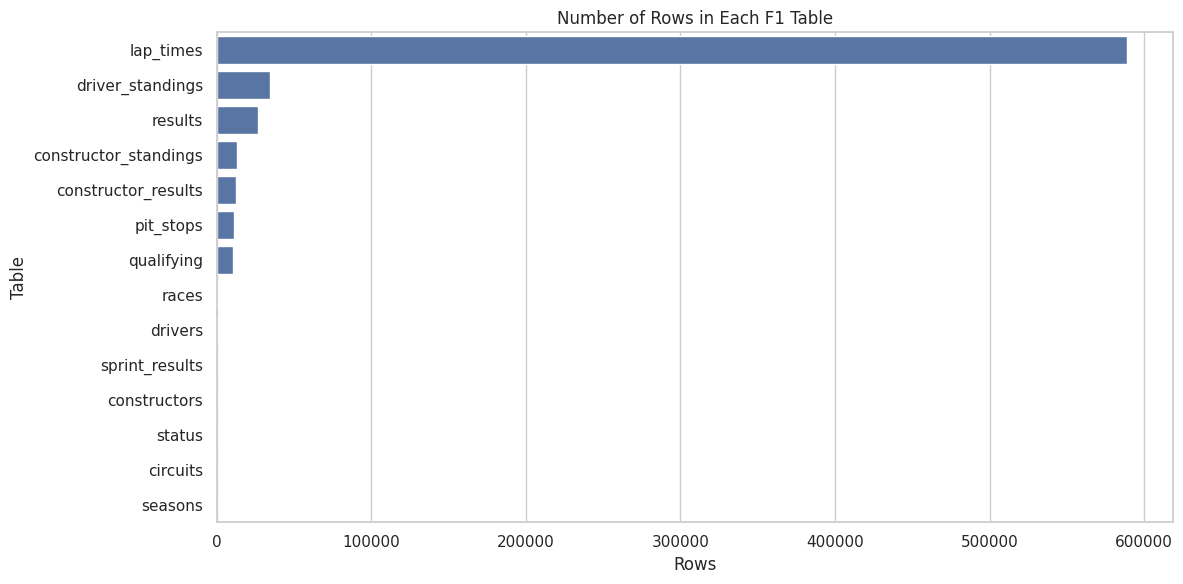

In [117]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=table_summary.sort_values('Rows', ascending=False),
    x='Rows',
    y='Table'
)

plt.title('Number of Rows in Each F1 Table')
plt.xlabel('Rows')
plt.ylabel('Table')

savefig('eda_06')


In [118]:
sentinel_counts = []

for table_name, df in raw_tables.items():
    count = (df.astype(str) == r'\N').sum().sum()

    sentinel_counts.append({
        'Table': table_name,
        'Sentinel_Count': count
    })

sentinel_summary = pd.DataFrame(sentinel_counts)

sentinel_summary.sort_values(
    'Sentinel_Count',
    ascending=False
)


,Table,Sentinel_Count
7,results,122887
2,constructor_results,12608
8,qualifying,11600
6,races,11349
4,drivers,1559
11,sprint_results,73
5,driver_standings,0
3,constructor_standings,0
0,circuits,0
1,constructors,0


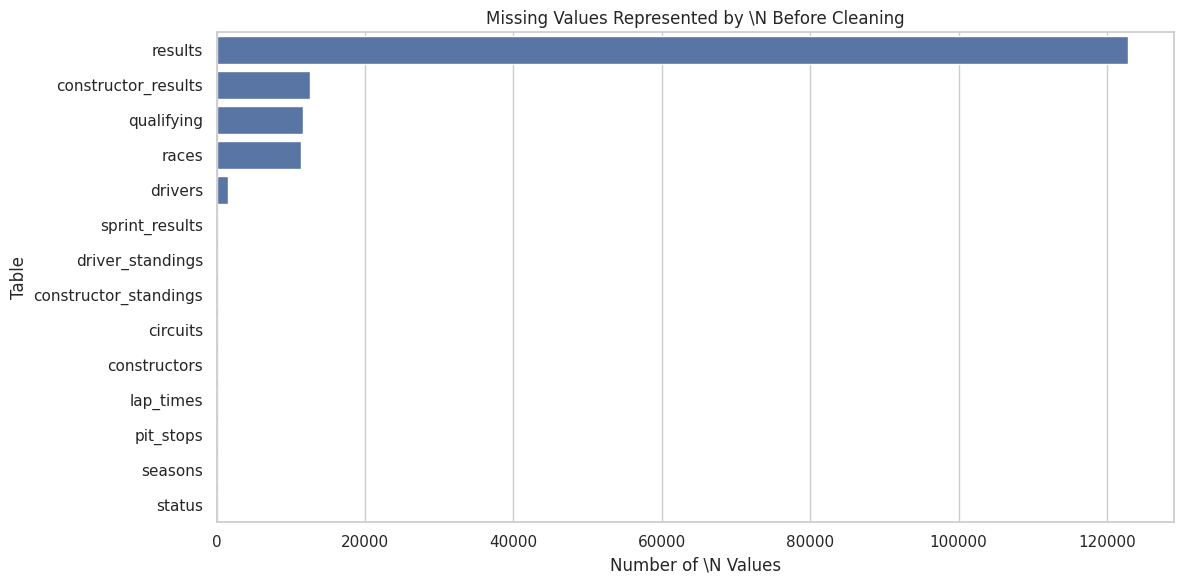

In [119]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=sentinel_summary.sort_values('Sentinel_Count', ascending=False),
    x='Sentinel_Count',
    y='Table'
)

plt.title(r'Missing Values Represented by \N Before Cleaning')
plt.xlabel(r'Number of \N Values')
plt.ylabel('Table')

savefig('eda_08')


In [120]:
results_raw = raw_tables['results']

results_raw.head()


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [121]:
results_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

In [122]:
results_raw.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
resultId,26759.0,NaN,NaN,NaN,13380.977391,7726.134642,1.0,6690.5,13380.0,20069.5,26764.0
raceId,26759.0,NaN,NaN,NaN,551.687283,313.265036,1.0,300.0,531.0,811.0,1144.0
driverId,26759.0,NaN,NaN,NaN,278.67353,282.703039,1.0,57.0,172.0,399.5,862.0
constructorId,26759.0,NaN,NaN,NaN,50.180537,61.551498,1.0,6.0,25.0,63.0,215.0
number,26759,130,4,1019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grid,26759.0,NaN,NaN,NaN,11.134796,7.20286,0.0,5.0,11.0,17.0,34.0
position,26759,34,\N,10953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positionText,26759,39,R,8897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positionOrder,26759.0,NaN,NaN,NaN,12.794051,7.665951,1.0,6.0,12.0,18.0,39.0
points,26759.0,NaN,NaN,NaN,1.987632,4.351209,0.0,0.0,0.0,2.0,50.0


In [123]:
results_eda = results_raw.copy()

results_eda['podium'] = (
    pd.to_numeric(
        results_eda['positionOrder'],
        errors='coerce'
    ) <= 3
).astype(int)


In [124]:
results_eda['podium'].value_counts()


podium
0    23362
1     3397
Name: count, dtype: int64

In [125]:
results_eda['podium'].value_counts(normalize=True) * 100


podium
0    87.305206
1    12.694794
Name: proportion, dtype: float64

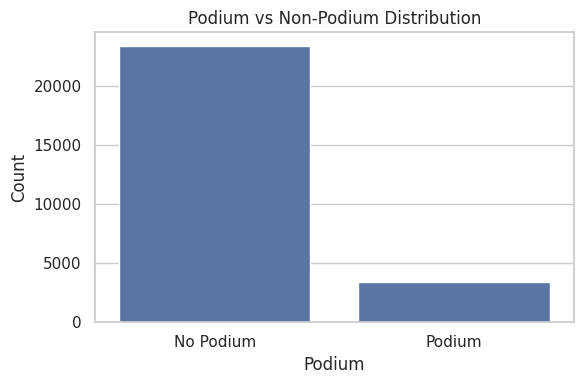

In [126]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=results_eda,
    x='podium'
)

plt.title('Podium vs Non-Podium Distribution')
plt.xlabel('Podium')
plt.ylabel('Count')

plt.xticks(
    [0, 1],
    ['No Podium', 'Podium']
)

savefig('eda_15')


In [127]:
# Driver-race rows from results
qual_coverage = raw_tables['results'][['raceId', 'driverId']].copy()

# Add race year
qual_coverage = qual_coverage.merge(
    raw_tables['races'][['raceId', 'year']],
    on='raceId',
    how='left'
)

# Unique driver-race combinations that exist in qualifying.csv
qual_keys = (
    raw_tables['qualifying'][['raceId', 'driverId']]
    .drop_duplicates()
    .copy()
)

qual_keys['has_qualifying'] = 1

# Check whether each driver-race result has qualifying data
qual_coverage = qual_coverage.merge(
    qual_keys,
    on=['raceId', 'driverId'],
    how='left'
)

qual_coverage['has_qualifying'] = (
    qual_coverage['has_qualifying']
    .fillna(0)
    .astype(int)
)

# Percentage coverage per year
qualifying_coverage = (
    qual_coverage.groupby('year')['has_qualifying']
    .mean()
    .mul(100)
    .reset_index(name='Qualifying_Coverage_Percent')
)

qualifying_coverage.tail(20)


,year,Qualifying_Coverage_Percent
55,2005,100.000000
56,2006,100.000000
57,2007,100.000000
58,2008,100.000000
59,2009,100.000000
60,2010,100.000000
61,2011,99.122807
62,2012,99.166667
63,2013,100.000000
64,2014,99.508600


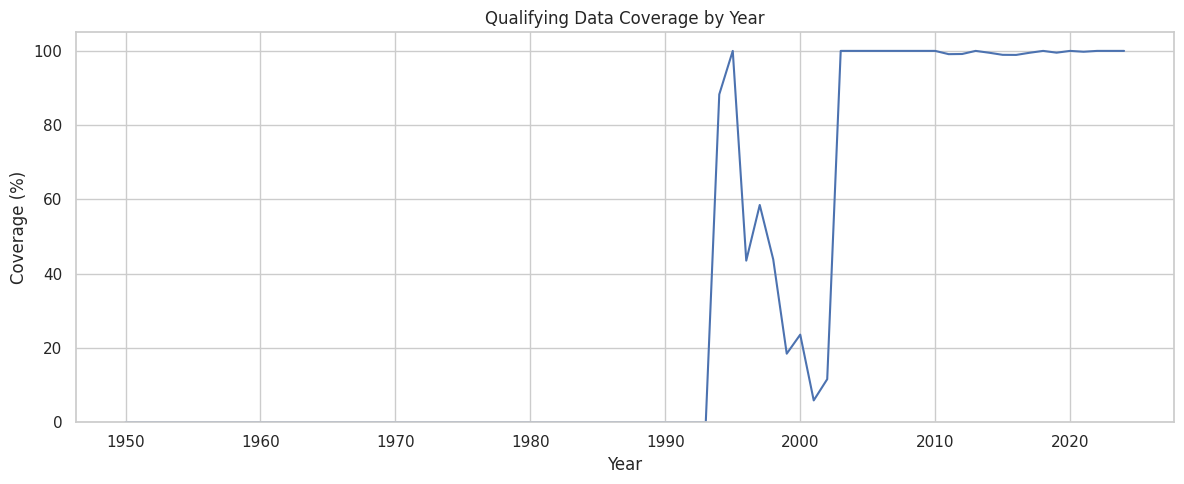

In [128]:
plt.figure(figsize=(12, 5))

plt.plot(
    qualifying_coverage['year'],
    qualifying_coverage['Qualifying_Coverage_Percent']
)

plt.title('Qualifying Data Coverage by Year')
plt.xlabel('Year')
plt.ylabel('Coverage (%)')
plt.ylim(0, 105)

savefig('eda_17')


In [129]:
grid_eda = pd.to_numeric(
    raw_tables['results']['grid'],
    errors='coerce'
)

print(grid_eda.describe())

print("\nGrid = 0 rows:")
print((grid_eda == 0).sum())


count    26759.000000
mean        11.134796
std          7.202860
min          0.000000
25%          5.000000
50%         11.000000
75%         17.000000
max         34.000000
Name: grid, dtype: float64

Grid = 0 rows:
1638


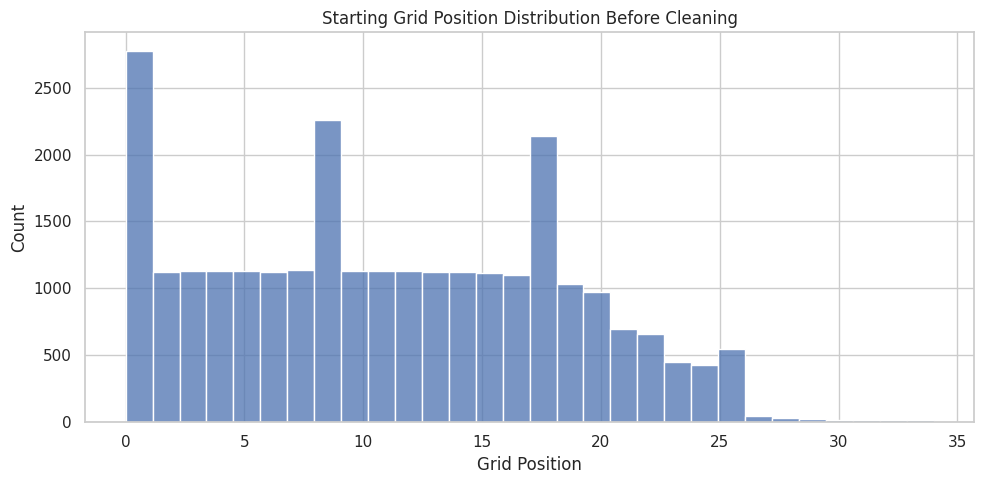

In [130]:
plt.figure(figsize=(10, 5))

sns.histplot(
    grid_eda,
    bins=30
)

plt.title('Starting Grid Position Distribution Before Cleaning')
plt.xlabel('Grid Position')
plt.ylabel('Count')

savefig('eda_19')


In [131]:
entrants = (
    raw_tables['results']
    .groupby('raceId')
    .size()
    .reset_index(name='Entrants')
)

entrants = entrants.merge(
    raw_tables['races'][['raceId', 'year']],
    on='raceId',
    how='left'
)

entrants_by_year = (
    entrants.groupby('year')['Entrants']
    .mean()
    .reset_index()
)

entrants_by_year.head()


,year,Entrants
0,1950,22.857143
1,1951,22.375000
2,1952,26.875000
3,1953,27.333333
4,1954,25.555556


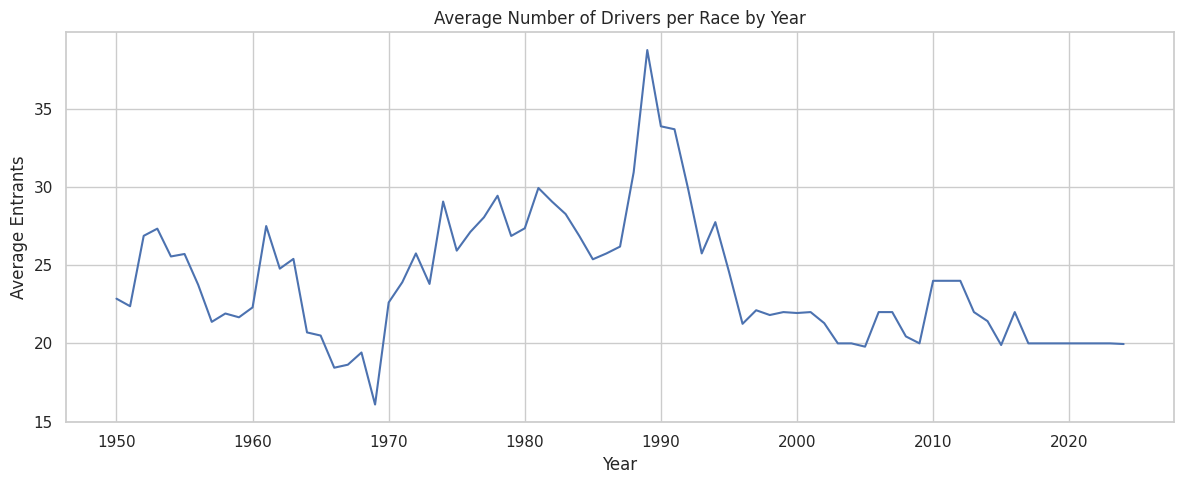

In [132]:
plt.figure(figsize=(12, 5))

plt.plot(
    entrants_by_year['year'],
    entrants_by_year['Entrants']
)

plt.title('Average Number of Drivers per Race by Year')
plt.xlabel('Year')
plt.ylabel('Average Entrants')

savefig('eda_21')


## 3. Cleaning and semantic typing
Convert sentinels on copies, numeric IDs consistently across tables, race dates and driver birth dates to datetimes, and durations to seconds. Missing data are preserved here; imputers are fitted later on training data only. Grid zero is not treated as pole position: it can represent a pit-lane/non-standard start or non-starter.

In [133]:
for table_name in tables:
    tables[table_name] = tables[table_name].replace({r'\N': np.nan, '': np.nan})

print("Sentinels replaced.")


Sentinels replaced.


In [134]:
remaining_sentinels = 0

for table_name, df in tables.items():
    remaining_sentinels += (df.astype(str) == r'\N').sum().sum()

print("Remaining \\N values:", remaining_sentinels)


Remaining \N values: 0


In [135]:
for name, df in tables.items():
    for col in df:
        if col.endswith('Id') or col in ['year','round','lap','stop','grid','position',
             'positionOrder','points','wins','laps','milliseconds','number','rank',
             'fastestLap','fastestLapSpeed','lat','lng','alt']:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        if col == 'date' or col.endswith('_date') or col == 'dob':
            df[col] = pd.to_datetime(df[col], errors='coerce')
def time_to_seconds(value):
    if pd.isna(value): return np.nan
    try:
        parts = [float(p) for p in str(value).split(':')]
        return sum(v * 60**i for i,v in enumerate(reversed(parts)))
    except (ValueError, TypeError): return np.nan
for col in ['q1','q2','q3']:
    tables['qualifying'][col+'_seconds'] = tables['qualifying'][col].map(time_to_seconds)
for name, col, new in [('results','fastestLapTime','fastestLapTime_seconds'),
                       ('lap_times','time','lapTime_seconds'),
                       ('pit_stops','duration','duration_seconds')]:
    if col in tables[name]: tables[name][new] = tables[name][col].map(time_to_seconds)
display(tables['races'][[c for c in tables['races'] if c=='date' or c.endswith('_date')]].dtypes)


date           datetime64[ns]
fp1_date       datetime64[ns]
fp2_date       datetime64[ns]
fp3_date       datetime64[ns]
quali_date     datetime64[ns]
sprint_date    datetime64[ns]
dtype: object

### Shared-drive duplicate rule
Prefer a row with a positive starting-grid assignment, then the smallest `resultId` as a deterministic tie-break. This avoids choosing the best finish as the duplicate rule. It is still an approximation for shared drives, because driver–race cannot represent multiple cars. Modern modeling (2014–2024) avoids the main shared-drive era. Grid-positive is a row-selection preference, **not** a complete test of whether a driver started.

In [136]:
results_clean = tables['results'].copy()

duplicate_mask = results_clean.duplicated(
    subset=['raceId', 'driverId'],
    keep=False
)

duplicate_driver_races = results_clean[
    duplicate_mask
].sort_values(
    ['raceId', 'driverId']
)

print(
    "Duplicate rows:",
    len(duplicate_driver_races)
)

print(
    "Duplicate driver-race combinations:",
    duplicate_driver_races[
        ['raceId', 'driverId']
    ].drop_duplicates().shape[0]
)

duplicate_driver_races[
    [
        'raceId',
        'driverId',
        'constructorId',
        'grid',
        'positionOrder'
    ]
].head(20)


Duplicate rows: 176
Duplicate driver-race combinations: 85


,raceId,driverId,constructorId,grid,positionOrder
13188,540,229,54,0,26
13191,540,229,57,0,29
17362,717,373,172,1,7
24298,717,373,172,1,12
17740,733,465,172,0,22
17743,733,465,97,0,25
17961,742,475,102,20,19
17963,742,475,172,5,21
18062,745,418,172,11,17
24297,745,418,172,15,11


In [137]:
r = tables['results'].copy()
r['_grid_assigned'] = r['grid'].gt(0).astype(int)
r = r.sort_values(['raceId','driverId','_grid_assigned','resultId'],
                  ascending=[True,True,False,True], kind='stable')
tables['results'] = r.drop_duplicates(['raceId','driverId']).drop(columns='_grid_assigned')
assert not tables['results'].duplicated(['raceId','driverId']).any()
assert tables['results']['positionOrder'].notna().all(), 'Unknown targets require investigation.'
tables['results']['podium'] = tables['results']['positionOrder'].le(3).astype(int)
print('Shared-drive rows removed:', len(raw_tables['results'])-len(tables['results']))


Shared-drive rows removed: 91


### Primary- and foreign-key auditing
Audit primary keys on the original cleaned tables (before shared-drive reduction), as well as the final driver–race grain. Every relationship below is checked; invalid references are exported. Stop on invalid keys rather than silently multiply rows.

In [138]:
primary_keys = {
    'circuits': ['circuitId'],
    'constructors': ['constructorId'],
    'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'drivers': ['driverId'],
    'driver_standings': ['driverStandingsId'],
    'races': ['raceId'],
    'results': ['resultId'],
    'qualifying': ['qualifyId'],
    'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'],
    'sprint_results': ['resultId'],
    'seasons': ['year'],
    'status': ['statusId']
}

pk_results = []

for table_name, keys in primary_keys.items():

    df = raw_tables[table_name].replace({r'\N': np.nan, '': np.nan})

    duplicate_count = df.duplicated(
        subset=keys
    ).sum()

    null_count = df[keys].isnull().any(
        axis=1
    ).sum()

    pk_results.append({
        'Table': table_name,
        'Primary_Key': ', '.join(keys),
        'Duplicate_PKs': duplicate_count,
        'Null_PKs': null_count
    })

pk_check = pd.DataFrame(pk_results)

pk_check


,Table,Primary_Key,Duplicate_PKs,Null_PKs
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId, driverId, lap",0,0


In [139]:
foreign_keys = [
 ('races','circuitId','circuits','circuitId'), ('races','year','seasons','year')]
for child in ['results','qualifying','lap_times','pit_stops','driver_standings','sprint_results']:
    foreign_keys += [(child,'raceId','races','raceId'), (child,'driverId','drivers','driverId')]
for child in ['results','qualifying','constructor_results','constructor_standings','sprint_results']:
    foreign_keys += [(child,'constructorId','constructors','constructorId')]
for child in ['constructor_results','constructor_standings']:
    foreign_keys.append((child,'raceId','races','raceId'))
for child in ['results','sprint_results']:
    foreign_keys.append((child,'statusId','status','statusId'))
fk_check = pd.DataFrame([{
 'Foreign_Key': f'{child}.{col}', 'References': f'{parent}.{key}',
 'Null_Values': int(raw_tables[child][col].replace({r'\N': np.nan, '': np.nan}).isna().sum()),
 'Invalid_Values': int((raw_tables[child][col].replace({r'\N': np.nan, '': np.nan}).notna() &
                  ~raw_tables[child][col].replace({r'\N': np.nan, '': np.nan}).isin(tables[parent][key])).sum())}
 for child,col,parent,key in foreign_keys])
display(pk_check); display(fk_check)
pk_check.to_csv(OUT/'primary_key_audit.csv',index=False)
fk_check.to_csv(OUT/'foreign_key_audit.csv',index=False)
assert pk_check[['Duplicate_PKs','Null_PKs']].to_numpy().sum()==0, 'Resolve invalid primary keys.'
assert fk_check[['Invalid_Values','Null_Values']].to_numpy().sum()==0, 'Resolve invalid foreign keys.'


,Table,Primary_Key,Duplicate_PKs,Null_PKs
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId, driverId, lap",0,0


,Foreign_Key,References,Null_Values,Invalid_Values
0,races.circuitId,circuits.circuitId,0,0
1,races.year,seasons.year,0,0
2,results.raceId,races.raceId,0,0
3,results.driverId,drivers.driverId,0,0
4,qualifying.raceId,races.raceId,0,0
5,qualifying.driverId,drivers.driverId,0,0
6,lap_times.raceId,races.raceId,0,0
7,lap_times.driverId,drivers.driverId,0,0
8,pit_stops.raceId,races.raceId,0,0
9,pit_stops.driverId,drivers.driverId,0,0


In [140]:
cleaning_summary = []

for table_name, df in tables.items():

    sentinel_count = (
        df.astype(str) == r'\N'
    ).sum().sum()

    missing_count = df.isnull().sum().sum()

    cleaning_summary.append({
        'Table': table_name,
        'Remaining_Sentinels': sentinel_count,
        'Missing_Values': missing_count
    })

cleaning_summary = pd.DataFrame(
    cleaning_summary
)

cleaning_summary


,Table,Remaining_Sentinels,Missing_Values
0,circuits,0,0
1,constructors,0,0
2,constructor_results,0,12608
3,constructor_standings,0,0
4,drivers,0,1559
5,driver_standings,0,0
6,races,0,11349
7,results,0,140755
8,qualifying,0,23336
9,lap_times,0,0


,table,raw_rows,clean_rows,raw_missing_or_sentinel,clean_missing
0,circuits,77,77,0,0
1,constructors,212,212,0,0
2,constructor_results,12625,12625,12608,12608
3,constructor_standings,13391,13391,0,0
4,drivers,861,861,1559,1559
5,driver_standings,34863,34863,0,0
6,races,1125,1125,11349,11349
7,results,26759,26668,122887,140755
8,qualifying,10494,10494,11668,23336
9,lap_times,589081,589081,0,0


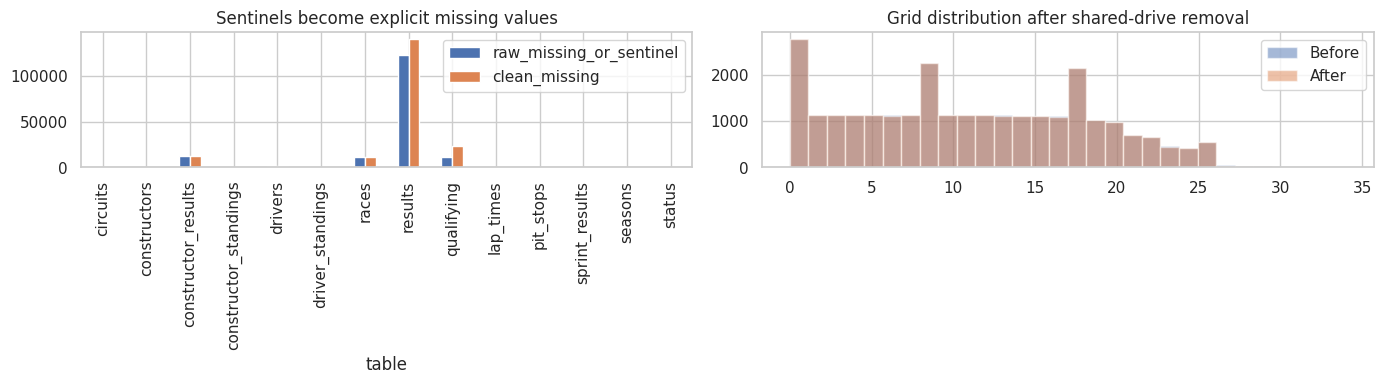

### Cleaning outcome
Removed 91 shared-drive rows; all 14 primary-key and 23 foreign-key checks passed. Missing values are retained for train-only imputation, not replaced using the whole dataset. Dates and durations are semantically typed; figure compares missingness and grid distributions.

In [141]:
before_after = pd.DataFrame({
 'table': file_names,
 'raw_rows': [len(raw_tables[n]) for n in file_names],
 'clean_rows': [len(tables[n]) for n in file_names],
 'raw_missing_or_sentinel': [int((raw_tables[n].isna() | raw_tables[n].eq(r'\N') |
                                  raw_tables[n].eq('')).sum().sum()) for n in file_names],
 'clean_missing': [int(tables[n].isna().sum().sum()) for n in file_names]})
display(before_after)
fig, axes = plt.subplots(1,2,figsize=(14,4))
before_after.set_index('table')[['raw_missing_or_sentinel','clean_missing']].plot.bar(ax=axes[0])
axes[0].set_title('Sentinels become explicit missing values')
raw_grid = pd.to_numeric(raw_tables['results']['grid'],errors='coerce')
axes[1].hist(raw_grid.dropna(),bins=30,alpha=.5,label='Before')
axes[1].hist(tables['results']['grid'].dropna(),bins=30,alpha=.5,label='After')
axes[1].set_title('Grid distribution after shared-drive removal'); axes[1].legend()
savefig('cleaning_before_after')
finding('Cleaning outcome', f"Removed {len(raw_tables['results'])-len(tables['results'])} shared-drive rows; "
 f"all {len(pk_check)} primary-key and {len(fk_check)} foreign-key checks passed. "
 'Missing values are retained for train-only imputation, not replaced using the whole dataset. '
 'Dates and durations are semantically typed; figure compares missingness and grid distributions.')


## 4. Data-engineering answers
### Q1. Front-row podium conversion before versus after 2014
Results → races → circuits and qualifying. Both grid and qualifying front rows are analyzed separately. Denominator = observed front-row driver–race records. Missing qualifying records are excluded only from that analysis. A minimum of 10 starts is used for the displayed rankings; all counts remain in CSV. The complete historical window is capped at 2024.

In [142]:
q1 = tables['results'][['raceId','driverId','grid','podium']].merge(
    tables['races'][['raceId','year','circuitId']],on='raceId',validate='many_to_one').merge(
    tables['circuits'][['circuitId','name']].rename(columns={'name':'circuit'}),
    on='circuitId',validate='many_to_one')
q1 = q1[q1.year.le(2024)].copy()
q1['Era'] = np.where(q1.year.lt(2014),'Before 2014','2014-2024')
qual_positions = tables['qualifying'].sort_values('qualifyId').drop_duplicates(['raceId','driverId'])[
    ['raceId','driverId','position']].rename(columns={'position':'qualifying_position'})
q1 = q1.merge(qual_positions,on=['raceId','driverId'],how='left',validate='one_to_one')
q1_rates = []
for source,column in [('Grid','grid'),('Qualifying','qualifying_position')]:
    rates = q1[q1[column].isin([1,2])].groupby(['Era','circuit']).podium.agg(
        Entries='size',Podiums='sum',Rate='mean').reset_index()
    rates['Source'] = source; rates['Rate'] *= 100
    rates['Rank'] = rates.groupby('Era')['Rate'].rank(method='min',ascending=False)
    q1_rates.append(rates)
q1_rates = pd.concat(q1_rates,ignore_index=True)
q1_rates.to_csv(OUT/'q1_front_row_rates.csv',index=False)
display(q1_rates.sort_values(['Source','Era','Rate'],ascending=[True,True,False]))


,Era,circuit,Entries,Podiums,Rate,Source,Rank
2,2014-2024,Autodromo Internazionale del Mugello,2,2,100.000000,Grid,1.0
5,2014-2024,Autódromo Internacional do Algarve,4,4,100.000000,Grid,1.0
20,2014-2024,Las Vegas Strip Street Circuit,4,4,100.000000,Grid,1.0
23,2014-2024,Miami International Autodrome,6,6,100.000000,Grid,1.0
30,2014-2024,Suzuka Circuit,18,16,88.888889,Grid,5.0
...,...,...,...,...,...,...,...
134,Before 2014,Albert Park Grand Prix Circuit,32,17,53.125000,Qualifying,28.0
133,Before 2014,Adelaide Street Circuit,4,2,50.000000,Qualifying,29.0
138,Before 2014,Autódromo Juan y Oscar Gálvez,8,4,50.000000,Qualifying,29.0
149,Before 2014,Fuji Speedway,4,2,50.000000,Qualifying,29.0


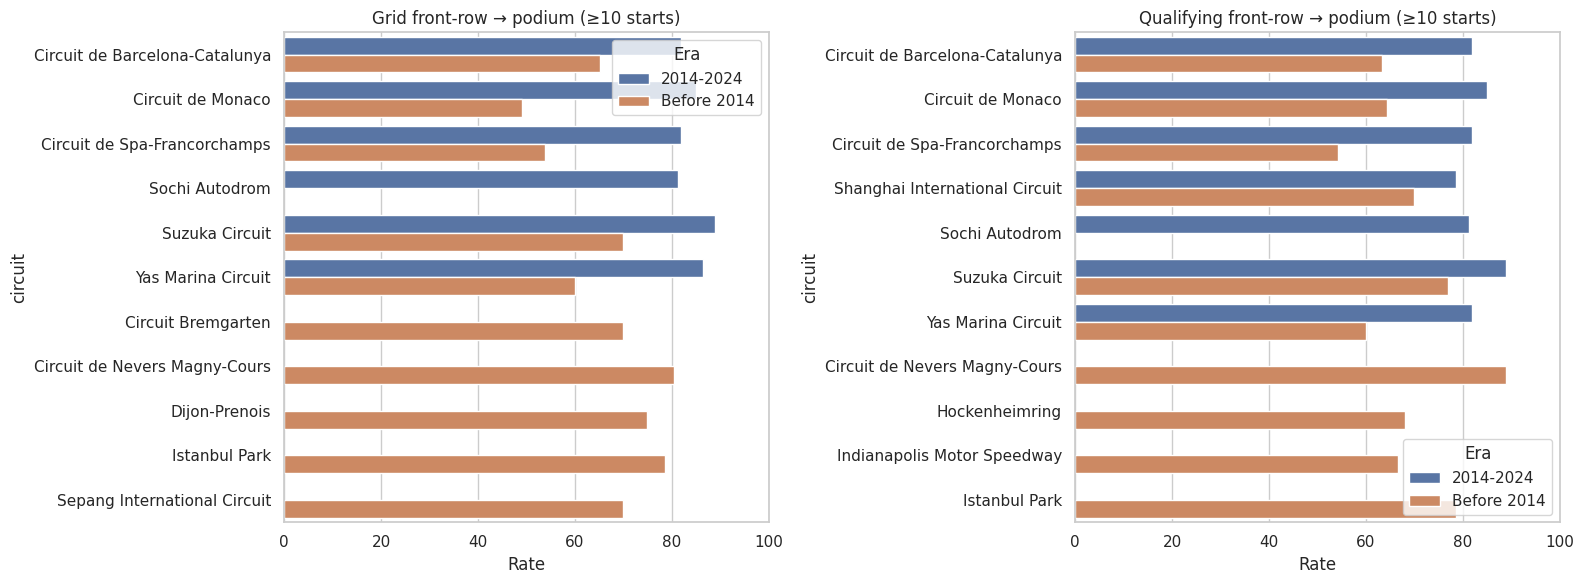

### Answer 1: circuit conversion
Grid / Before 2014: Circuit de Nevers Magny-Cours 80.6% (29/36); Istanbul Park 78.6% (11/14); Dijon-Prenois 75.0% (9/12). Grid / 2014-2024: Suzuka Circuit 88.9% (16/18); Yas Marina Circuit 86.4% (19/22); Circuit de Monaco 85.0% (17/20). Qualifying / Before 2014: Circuit de Nevers Magny-Cours 88.9% (16/18); Istanbul Park 78.6% (11/14); Suzuka Circuit 76.9% (20/26). Qualifying / 2014-2024: Suzuka Circuit 88.9% (16/18); Circuit de Monaco 85.0% (17/20); Circuit de Barcelona-Catalunya 81.8% (18/22). Among 16 circuits observed in both eras, 15 have different relative ranks (ties use average ranks). These are descriptive rates, sensitive to sample size and qualifying coverage. Qualifying rank differs from final grid because of penalties and race-weekend rules.

In [143]:
fig, axes = plt.subplots(1,2,figsize=(16,6))
for ax,source in zip(axes,['Grid','Qualifying']):
    rates = q1_rates[(q1_rates.Source==source)&(q1_rates.Entries>=10)]
    top = rates.sort_values('Rate',ascending=False).groupby('Era').head(6).circuit.unique()
    if len(top):
        sns.barplot(data=rates[rates.circuit.isin(top)],x='Rate',y='circuit',hue='Era',ax=ax)
    else: ax.text(.1,.5,'Insufficient front-row sample',transform=ax.transAxes)
    ax.set_title(source+' front-row → podium (≥10 starts)'); ax.set_xlim(0,100)
savefig('q1_front_row_conversion')
parts=[]
for source in ['Grid','Qualifying']:
    for era in ['Before 2014','2014-2024']:
        eligible=q1_rates[(q1_rates.Source==source)&(q1_rates.Era==era)&(q1_rates.Entries>=10)]
        leaders=eligible.sort_values(['Rate','Entries'],ascending=False).head(3)
        parts.append(source+' / '+era+': '+('; '.join(
            f'{r.circuit} {r.Rate:.1f}% ({r.Podiums}/{r.Entries})' for r in leaders.itertuples())
            if len(leaders) else 'insufficient observations')+'.')
common=q1_rates[q1_rates.Source.eq('Grid')&q1_rates.Entries.ge(10)].pivot(
    index='circuit',columns='Era',values='Rate').dropna()
if {'Before 2014','2014-2024'}.issubset(common.columns) and len(common)>1:
    rank_changes=(common['Before 2014'].rank(ascending=False)-common['2014-2024'].rank(ascending=False)).abs()
    parts.append(f'Among {len(common)} circuits observed in both eras, {int(rank_changes.gt(0).sum())} '
                 'have different relative ranks (ties use average ranks).')
parts.append('These are descriptive rates, sensitive to sample size and qualifying coverage. '
             'Qualifying rank differs from final grid because of penalties and race-weekend rules.')
finding('Answer 1: circuit conversion', ' '.join(parts))


### Q2. Home versus away within starting-position groups
Results → races → circuits → drivers. Nationality labels are stripped of whitespace before mapping. Hyphenated dual nationalities are not forced into one country; those rows are excluded from the Q2 home/away comparison. Nationality remains only a proxy for home country, not residence. Unknown mappings are excluded and disclosed; zero/non-positive grids are excluded from the ranked-grid comparison. Grid strata reduce starting-position confounding but do not control driver quality, constructor, or era.

In [144]:
nationality_to_country = {
    'American': 'USA',
    'Argentine': 'Argentina',
    'Argentinian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela'
}
def map_nationality_to_country(series):
    """
    Normalize nationality labels before mapping.

    Policy:
    - Strip leading/trailing whitespace.
    - Single nationalities are mapped to one country.
    - Hyphenated dual nationalities are left unmapped because assigning
      one country would be arbitrary.
    """
    cleaned = series.astype('string').str.strip()

    dual_mask = cleaned.str.contains(
        '-',
        regex=False,
        na=False
    )

    mapped = cleaned.map(nationality_to_country)

    # Do not force dual nationalities into one home country
    mapped = mapped.mask(dual_mask)

    return cleaned, mapped, dual_mask

Unmapped single nationalities: <StringArray>
[]
Length: 0, dtype: string
Dual nationalities excluded: <StringArray>
['American-Italian', 'Argentine-Italian']
Length: 2, dtype: string


,grid_group,home_race,Entries,Podiums,Podium_Rate,Location
0,1-2,False,2067,1246,60.280600,Away
1,1-2,True,183,99,54.098361,Home
2,3-5,False,3133,1091,34.822853,Away
3,3-5,True,251,96,38.247012,Home
4,6-10,False,5146,577,11.212592,Away
5,6-10,True,475,43,9.052632,Home
6,11-15,False,5125,152,2.965854,Away
7,11-15,True,471,15,3.184713,Home
8,16-20,False,4738,41,0.865344,Away
9,16-20,True,496,3,0.604839,Home


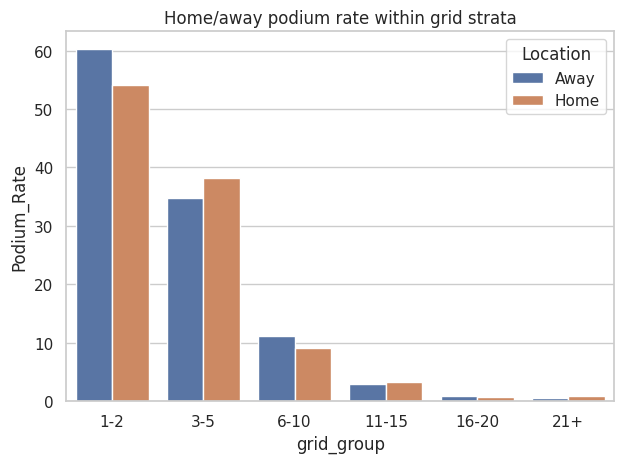

In [145]:
nationality_to_country.update({'East German':'Germany',
 'Rhodesian':'Zimbabwe','Liechtensteiner':'Liechtenstein'})
q2 = tables['results'][['raceId','driverId','grid','podium']].merge(
 tables['races'][['raceId','circuitId','year']],on='raceId',validate='many_to_one').merge(
 tables['circuits'][['circuitId','country']],on='circuitId',validate='many_to_one').merge(
 tables['drivers'][['driverId','nationality']],on='driverId',validate='many_to_one')
q2=q2[q2.year.le(2024)].copy()
nationality_clean, mapped_country, dual_mask = (
    map_nationality_to_country(q2['nationality'])
)

q2['nationality_clean'] = nationality_clean
q2['driver_country'] = mapped_country

dual_home = int(dual_mask.sum())

unmapped_single_home = int(
    (
        q2['driver_country'].isna()
        & ~dual_mask
        & q2['nationality_clean'].notna()
    ).sum()
)

print(
    'Unmapped single nationalities:',
    q2.loc[
        q2['driver_country'].isna() & ~dual_mask,
        'nationality_clean'
    ].unique()
)

print(
    'Dual nationalities excluded:',
    q2.loc[
        dual_mask,
        'nationality_clean'
    ].unique()
)
q2=q2[q2.driver_country.notna() & q2.country.notna() & q2.grid.gt(0)].copy()
q2['home_race']=q2.driver_country.eq(q2.country)
q2['grid_group']=pd.cut(q2.grid,[0,2,5,10,15,20,np.inf],labels=['1-2','3-5','6-10','11-15','16-20','21+'])
home_analysis=q2.groupby(['grid_group','home_race'],observed=True).podium.agg(
 Entries='size',Podiums='sum',Podium_Rate='mean').reset_index()
home_analysis['Podium_Rate'] *=100
home_analysis['Location']=home_analysis.home_race.map({True:'Home',False:'Away'})
display(home_analysis); home_analysis.to_csv(OUT/'q2_home_rates.csv',index=False)
sns.barplot(data=home_analysis,x='grid_group',y='Podium_Rate',hue='Location')
plt.title('Home/away podium rate within grid strata'); savefig('q2_home_advantage')


In [146]:
wide = home_analysis.pivot(
    index='grid_group',
    columns='Location',
    values='Podium_Rate'
)

common = wide.dropna()

weights = (
    q2.groupby('grid_group', observed=True)
      .size()
      .reindex(common.index)
)

if {'Home', 'Away'}.issubset(common.columns) and len(common):
    weights = weights / weights.sum()

    home_rate = float((common.Home * weights).sum())
    away_rate = float((common.Away * weights).sum())

    answer = (
        f'Using the same pooled grid-stratum weights, home podium rate is '
        f'{home_rate:.2f}% and away rate is {away_rate:.2f}% '
        f'(difference {home_rate-away_rate:+.2f} percentage points). '
    )

    answer += (
        'Within-stratum differences: '
        + ', '.join(
            f'{idx}: {r.Home-r.Away:+.2f} pp'
            for idx, r in common.iterrows()
        )
        + '. '
    )

else:
    answer = (
        'There are insufficient overlapping home/away strata '
        'for standardization. '
    )


finding(
    'Answer 2: home association',
    answer
    + f'{unmapped_single_home} rows with unmapped single-nationality labels '
      'were excluded. '
    + f'{dual_home} dual-nationality rows were intentionally excluded rather '
      'than forcing them into one home country. '
    + 'Nationality is only a proxy for home country. '
      'This is an association, not evidence of a causal home advantage. '
      'Broad grid groups retain residual confounding; '
      'small home groups are unstable.'
)

### Answer 2: home association
Using the same pooled grid-stratum weights, home podium rate is 13.01% and away rate is 13.55% (difference -0.53 percentage points). Within-stratum differences: 1-2: -6.18 pp, 3-5: +3.42 pp, 6-10: -2.16 pp, 11-15: +0.22 pp, 16-20: -0.26 pp, 21+: +0.42 pp. 0 rows with unmapped single-nationality labels were excluded. 4 dual-nationality rows were intentionally excluded rather than forcing them into one home country. Nationality is only a proxy for home country. This is an association, not evidence of a causal home advantage. Broad grid groups retain residual confounding; small home groups are unstable.

### Q3. Mechanical retirements by constructor
Results → races → constructors → status. Denominator = starts excluding explicit non-start statuses, including pit-lane starts. Retirements must complete fewer laps than the race maximum and have a mechanical status. Mechanical labels are matched **exactly**, displayed, and exclude accidents, driver errors, regulation decisions and ambiguous labels. This conservative taxonomy can undercount ambiguous failures; constructor renamings remain separate identities.

Non-start statuses remaining: []


,status,mechanical_retirement,Count
0,+1 Lap,0,1178
1,+2 Laps,0,208
2,+3 Laps,0,24
3,+4 Laps,0,6
4,+5 Laps,0,1
...,...,...,...
61,Water leak,1,4
62,Water pressure,1,7
63,Water pump,1,1
64,Wheel,0,11


,Era,constructor,Race_Starts,Mechanical_Retirements,Mechanical_Retirement_Rate
4,2014-2021,Caterham,34,8,23.529412
8,2014-2021,Lotus F1,75,13,17.333333
17,2014-2021,Toro Rosso,242,39,16.115702
11,2014-2021,McLaren,318,43,13.522013
15,2014-2021,Renault,200,27,13.500000
16,2014-2021,Sauber,200,22,11.000000
14,2014-2021,Red Bull,319,33,10.344828
1,2014-2021,AlphaTauri,78,8,10.256410
10,2014-2021,Marussia,31,3,9.677419
13,2014-2021,Racing Point,76,7,9.210526


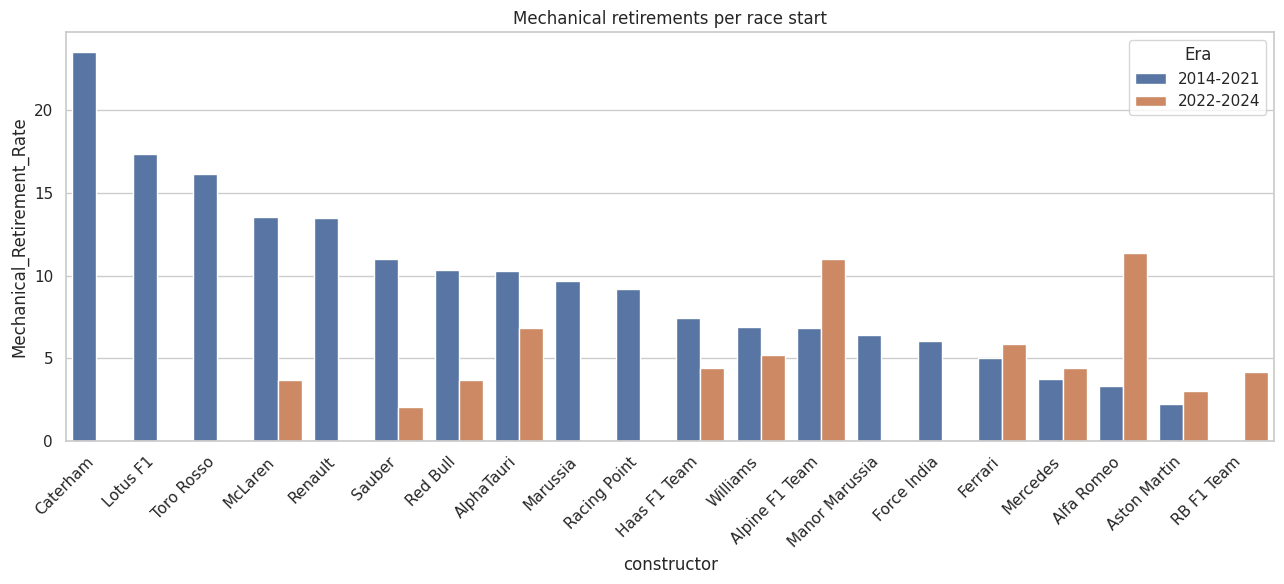

### Answer 3: mechanical reliability
2014-2021: Caterham: 23.5% (8/34); Lotus F1: 17.3% (13/75); Toro Rosso: 16.1% (39/242). 2022-2024: Alfa Romeo: 11.4% (10/88); Alpine F1 Team: 11.0% (15/136); AlphaTauri: 6.8% (6/88). Exact status labels define mechanical failures; unclassified/ambiguous labels are excluded from the numerator. Small constructor samples and team renamings limit comparisons.

In [147]:
non_start_statuses = {
    'Did not qualify',
    'Did not prequalify',
    'Did not start',
    'Withdrawn',
    'Withdrew',
    '107% Rule'
}

mechanical_statuses = {
    'Engine','Gearbox','Transmission','Clutch','Hydraulics','Electrical',
    'Electronics','Brakes','Differential','Radiator','Suspension','Driveshaft','Drivetrain',
    'Power Unit','Power unit','Turbo','ERS','Battery','Alternator','Ignition','Spark plugs',
    'Fuel pump','Fuel pressure','Fuel system','Fuel leak','Oil leak','Oil pressure','Oil pump',
    'Water leak','Water pump','Water pressure','Cooling system','Overheating','Exhaust',
    'Throttle','Steering','Axle','Halfshaft','Crankshaft','CV joint','Mechanical',
    'Power loss','Supercharger','Magneto','Distributor','Pneumatics','Injection','Track rod'
}

q3 = (
    tables['results'][
        ['raceId','driverId','constructorId','statusId','laps']
    ]
    .merge(
        tables['races'][['raceId','year']],
        on='raceId',
        validate='many_to_one'
    )
    .merge(
        tables['constructors'][['constructorId','name']]
        .rename(columns={'name':'constructor'}),
        on='constructorId',
        validate='many_to_one'
    )
    .merge(
        tables['status'],
        on='statusId',
        validate='many_to_one'
    )
)

q3 = q3[
    q3.year.between(2014, 2024)
    & ~q3.status.isin(non_start_statuses)
].copy()

# Audit: no known non-start status should remain
assert not q3['status'].isin(non_start_statuses).any()

print(
    "Non-start statuses remaining:",
    q3.loc[
        q3['status'].isin(non_start_statuses),
        'status'
    ].unique()
)

q3['Era'] = np.where(
    q3.year.le(2021),
    '2014-2021',
    '2022-2024'
)

# Zero laps can be a real start followed by immediate failure; do not exclude it.
race_completed_laps = (
    tables['results']
    .groupby('raceId')
    .laps
    .max()
)

q3['ended_early'] = q3.laps.lt(
    q3.raceId.map(race_completed_laps)
)

q3['mechanical_retirement'] = (
    q3.ended_early
    & q3.status.str.casefold().isin(
        {s.casefold() for s in mechanical_statuses}
    )
).astype(int)

q3.groupby(
    ['status','ended_early','mechanical_retirement']
).size().reset_index(
    name='Count'
).to_csv(
    OUT/'mechanical_status_audit.csv',
    index=False
)

display(
    q3.groupby(
        ['status','mechanical_retirement']
    ).size().reset_index(
        name='Count'
    )
)

constructor_rates = (
    q3.groupby(
        ['Era','constructor']
    ).mechanical_retirement.agg(
        Race_Starts='size',
        Mechanical_Retirements='sum',
        Mechanical_Retirement_Rate='mean'
    ).reset_index()
)

constructor_rates[
    'Mechanical_Retirement_Rate'
] *= 100

constructor_rates = constructor_rates.sort_values(
    ['Era','Mechanical_Retirement_Rate'],
    ascending=[True,False]
)

display(constructor_rates)

constructor_rates.to_csv(
    OUT/'q3_constructor_failures.csv',
    index=False
)

plt.figure(figsize=(13,6))

sns.barplot(
    data=constructor_rates,
    x='constructor',
    y='Mechanical_Retirement_Rate',
    hue='Era'
)

plt.xticks(
    rotation=45,
    ha='right'
)

plt.title(
    'Mechanical retirements per race start'
)

savefig(
    'q3_mechanical_retirements'
)

parts = []

for era in [
    '2014-2021',
    '2022-2024'
]:
    top = constructor_rates[
        constructor_rates.Era.eq(era)
    ].head(3)

    parts.append(
        era + ': '
        + '; '.join(
            f'{r.constructor}: '
            f'{r.Mechanical_Retirement_Rate:.1f}% '
            f'({r.Mechanical_Retirements}/{r.Race_Starts})'
            for r in top.itertuples()
        )
        + '.'
    )

finding(
    'Answer 3: mechanical reliability',
    ' '.join(parts)
    + ' Exact status labels define mechanical failures; '
      'unclassified/ambiguous labels are excluded from the numerator. '
      'Small constructor samples and team renamings limit comparisons.'
)

## 5. Leakage-safe feature engineering
Only retrospective outcomes can build form. Driver rolling form uses `shift(1)`; constructor form first aggregates the whole race, then shifts, so a teammate's same-race result cannot leak. Circuit form uses prior driver–circuit appearances. Previous championship snapshots use an as-of join with **strictly earlier race index in the same season**; first-round standings default to zero points/wins and unknown position. No current-race finishing position, points, status, laps, fastest lap, pit stop, or post-race standing appears in X.

Grid extracted from results.csv is its pre-start grid field; it is permitted by the brief. Retrospectively observed entrant lists and shared-drive records are limitations of this source. Future races are not used in imputation or encoding. Histories for validation/test races update with already completed earlier races, representing sequential deployment; the fitted model remains fixed.

In [148]:
calendar=tables['races'][['raceId','year','round','circuitId','date']].sort_values(['date','raceId']).copy()
assert calendar.date.notna().all(), 'Race dates must be known.'
calendar['event_index']=np.arange(len(calendar),dtype=np.int64)

def attach_prior_standings(frame, source, entity, prefix):
    right=source[['raceId',entity,'points','position','wins']].merge(
        calendar[['raceId','year','event_index']],on='raceId',validate='many_to_one')
    right=right.rename(columns={'event_index':prefix+'_snapshot_index',
        'points':prefix+'_points','position':prefix+'_position','wins':prefix+'_wins'})
    # asof keys must be globally sorted; by restricts entity and season.
    right=right.drop(columns='raceId').sort_values(prefix+'_snapshot_index')
    result=pd.merge_asof(frame.sort_values('event_index'),right,
        left_on='event_index',right_on=prefix+'_snapshot_index',by=[entity,'year'],
        direction='backward',allow_exact_matches=False)
    observed=result[prefix+'_snapshot_index'].notna()
    assert (result.loc[observed,prefix+'_snapshot_index']<result.loc[observed,'event_index']).all()
    first_round=result['round'].eq(1)
    for suffix in ['points','wins']:
        result.loc[first_round,prefix+'_'+suffix]=0
    return result

def build_modeling_table(
    result_table,
    driver_standings=None,
    constructor_standings=None
):
    if driver_standings is None:
        driver_standings = tables['driver_standings']

    if constructor_standings is None:
        constructor_standings = tables['constructor_standings']
    base=result_table[['raceId','driverId','constructorId','grid','podium','positionOrder','points']].merge(
        calendar,on='raceId',validate='many_to_one').sort_values(['event_index','driverId']).reset_index(drop=True)
    base['driver_podium_last5']=base.groupby('driverId').podium.transform(
        lambda s:s.shift(1).rolling(5,min_periods=1).mean())
    base['driver_finish_last5']=base.groupby('driverId').positionOrder.transform(
        lambda s:s.shift(1).rolling(5,min_periods=1).mean())
    base['driver_points_last5']=base.groupby('driverId').points.transform(
        lambda s:s.shift(1).rolling(5,min_periods=1).mean())
    # Historical results include non-starters; this feature counts entries, not confirmed starts.
    base['driver_prior_starts']=base.groupby('driverId').cumcount()
    base['circuit_prior_podium_rate']=base.groupby(['driverId','circuitId']).podium.transform(
        lambda s:s.shift(1).expanding(min_periods=1).mean())
    team=base.groupby(['event_index','constructorId'],as_index=False).agg(team_podium=('podium','mean'))
    team=team.sort_values('event_index')
    team['constructor_podium_last5']=team.groupby('constructorId').team_podium.transform(
        lambda s:s.shift(1).rolling(5,min_periods=1).mean())
    base=base.merge(team[['event_index','constructorId','constructor_podium_last5']],
        on=['event_index','constructorId'],validate='many_to_one')
    base = attach_prior_standings(
    base,
    driver_standings,
    'driverId',
    'driver_standing'
    )
    
    base = attach_prior_standings(
        base,
        constructor_standings,
        'constructorId',
        'constructor_standing'
    )
    qual=tables['qualifying'].sort_values('qualifyId').drop_duplicates(['raceId','driverId']).copy()
    qual=qual[['raceId','driverId','position','q1_seconds']].rename(columns={'position':'qualifying_position'})
    qual['q1_relative_gap']=qual.q1_seconds/qual.groupby('raceId').q1_seconds.transform('min')-1
    base=base.merge(qual[['raceId','driverId','qualifying_position','q1_relative_gap']],
                    on=['raceId','driverId'],how='left',validate='one_to_one')
    base=base.merge(tables['drivers'][['driverId','dob','nationality']],on='driverId',validate='many_to_one')
    base=base.merge(tables['circuits'][['circuitId','country']],on='circuitId',validate='many_to_one')
    base['age']=(base.date-base.dob).dt.days/365.25
    _, mapped, _ = map_nationality_to_country(
    base['nationality']
    )
    
    base['home_race'] = np.where(
        mapped.notna() & base.country.notna(),
        mapped.eq(base.country).astype(float),
        np.nan
    )
    base['grid_nonstandard']=base.grid.le(0).astype(int)
    base.loc[base.grid.le(0),'grid']=np.nan
    for col in ['driverId','constructorId','circuitId']:
        base[col+'_category']=base[col].map(lambda v:str(int(v)) if pd.notna(v) else 'unknown')
    return base.sort_values(['event_index','driverId']).reset_index(drop=True)
full_modeling=build_modeling_table(tables['results'])
modeling=full_modeling[full_modeling.year.between(2014,2024)].copy().reset_index(drop=True)
assert not modeling.duplicated(['raceId','driverId']).any()
print('Modeling rows:',len(modeling),'Seasons:', sorted(modeling.year.unique()))


Modeling rows: 4626 Seasons: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [149]:
feature_groups={
 'grid':['grid','grid_nonstandard'],
 'qualifying':['qualifying_position','q1_relative_gap'],
 'driver_form':['driver_podium_last5','driver_finish_last5','driver_points_last5','driver_prior_starts'],
 'constructor_form':['constructor_podium_last5'],
 'standings':['driver_standing_points','driver_standing_position','driver_standing_wins',
              'constructor_standing_points','constructor_standing_position','constructor_standing_wins'],
 'circuit_history':['circuit_prior_podium_rate'],
 'context':['age','home_race','round'],
 'identity':['driverId_category','constructorId_category','circuitId_category']}
FEATURES=[f for group in feature_groups.values() for f in group]
CAT=feature_groups['identity']; NUM=[f for f in FEATURES if f not in CAT]
forbidden={'podium','positionOrder','points','statusId','laps','milliseconds','fastestLapTime_seconds'}
assert not forbidden.intersection(FEATURES)
assert modeling[FEATURES].select_dtypes(include=np.number).replace([np.inf,-np.inf],np.nan).shape[1]==len(NUM)
modeling.to_csv(OUT/'driver_race_modeling_table.csv',index=False)
display(modeling[['raceId','driverId','year','podium']+FEATURES].head())
# ---------------------------------------------------------
# LEAKAGE TEST 1:
# Changing outcomes in an earlier race must NOT change
# features for that race or any race before it.
# ---------------------------------------------------------

test_events = calendar.loc[
    calendar['year'].isin([2016, 2019, 2022])
    & calendar['round'].eq(5),
    ['raceId', 'year', 'round', 'event_index']
].sort_values('event_index')

assert len(test_events) == 3, (
    "Expected one Round-5 test race in each of 2016, 2019 and 2022."
)

compare_cols = [
    'raceId',
    'driverId'
] + FEATURES

for event in test_events.itertuples(index=False):

    mutated_results = tables['results'].copy()

    race_mask = mutated_results['raceId'].eq(
        event.raceId
    )

    assert race_mask.any()

    # Deliberately alter post-race outcomes
    mutated_results.loc[
        race_mask,
        'podium'
    ] = (
        1
        - mutated_results.loc[
            race_mask,
            'podium'
        ].astype(int)
    )

    mutated_results.loc[
        race_mask,
        'points'
    ] = (
        mutated_results.loc[
            race_mask,
            'points'
        ].fillna(0)
        + 999
    )

    mutated_results.loc[
        race_mask,
        'positionOrder'
    ] = (
        mutated_results.loc[
            race_mask,
            'positionOrder'
        ].fillna(99)
        + 50
    )

    changed = build_modeling_table(
        mutated_results
    )

    original_before = (
        full_modeling.loc[
            full_modeling['event_index']
            <= event.event_index,
            compare_cols
        ]
        .reset_index(drop=True)
    )

    changed_before = (
        changed.loc[
            changed['event_index']
            <= event.event_index,
            compare_cols
        ]
        .reset_index(drop=True)
    )

    pd.testing.assert_frame_equal(
        original_before,
        changed_before,
        check_dtype=False
    )

print(
    'Passed result leakage tests for:',
    test_events[
        ['year', 'round', 'raceId']
    ].to_dict('records')
)


# ---------------------------------------------------------
# LEAKAGE TEST 2:
# Changing the CURRENT race's standings snapshot must not
# change features used for that same race.
# ---------------------------------------------------------

for event in test_events.itertuples(index=False):

    driver_standings_test = (
        tables['driver_standings'].copy()
    )

    constructor_standings_test = (
        tables['constructor_standings'].copy()
    )

    driver_mask = (
        driver_standings_test['raceId']
        .eq(event.raceId)
    )

    constructor_mask = (
        constructor_standings_test['raceId']
        .eq(event.raceId)
    )

    assert driver_mask.any()
    assert constructor_mask.any()

    # Make the current-race standings obviously different
    for frame, mask in [
        (driver_standings_test, driver_mask),
        (constructor_standings_test, constructor_mask)
    ]:
        frame.loc[mask, 'points'] = (
            frame.loc[mask, 'points']
            .fillna(0)
            + 10000
        )

        frame.loc[mask, 'position'] = (
            frame.loc[mask, 'position']
            .fillna(0)
            + 100
        )

        frame.loc[mask, 'wins'] = (
            frame.loc[mask, 'wins']
            .fillna(0)
            + 50
        )

    changed = build_modeling_table(
        tables['results'],
        driver_standings=driver_standings_test,
        constructor_standings=constructor_standings_test
    )

    original_current = (
        full_modeling.loc[
            full_modeling['raceId']
            .eq(event.raceId),
            compare_cols
        ]
        .sort_values(
            ['raceId', 'driverId']
        )
        .reset_index(drop=True)
    )

    changed_current = (
        changed.loc[
            changed['raceId']
            .eq(event.raceId),
            compare_cols
        ]
        .sort_values(
            ['raceId', 'driverId']
        )
        .reset_index(drop=True)
    )

    pd.testing.assert_frame_equal(
        original_current,
        changed_current,
        check_dtype=False
    )

print(
    'Passed current-race standings leakage tests for:',
    test_events[
        ['year', 'round', 'raceId']
    ].to_dict('records')
)


,raceId,driverId,year,podium,grid,grid_nonstandard,qualifying_position,q1_relative_gap,driver_podium_last5,driver_finish_last5,...,constructor_standing_points,constructor_standing_position,constructor_standing_wins,circuit_prior_podium_rate,age,home_race,round,driverId_category,constructorId_category,circuitId_category
0,900,1,2014,0,1.0,0,1.0,0.010179,0.0,9.2,...,0.0,NaN,0.0,0.571429,29.185489,0.0,1,1,131,1
1,900,3,2014,1,3.0,0,3.0,0.019708,0.4,5.4,...,0.0,NaN,0.0,0.125000,28.717317,0.0,1,3,131,1
2,900,4,2014,0,5.0,0,5.0,0.006753,0.2,5.6,...,0.0,NaN,0.0,0.416667,32.629706,0.0,1,4,6,1
3,900,8,2014,0,11.0,0,12.0,0.018331,0.4,7.8,...,0.0,NaN,0.0,0.454545,34.412047,0.0,1,8,6,1
4,900,13,2014,0,9.0,0,9.0,0.004990,0.0,8.4,...,0.0,NaN,0.0,0.090909,32.889802,0.0,1,13,3,1


Passed result leakage tests for: [{'year': 2016, 'round': 5, 'raceId': 952}, {'year': 2019, 'round': 5, 'raceId': 1014}, {'year': 2022, 'round': 5, 'raceId': 1078}]
Passed current-race standings leakage tests for: [{'year': 2016, 'round': 5, 'raceId': 952}, {'year': 2019, 'round': 5, 'raceId': 1014}, {'year': 2022, 'round': 5, 'raceId': 1078}]


## 6. Chronological train / validation / test split and feature evidence
Training: 2014–2020. Validation: 2021–2022. Unseen test: 2023–2024. Whole races stay together; chronological order simulates later seasons and prevents driver–race intermixing from the same weekend. All choices use training/validation only. Modern data reduce qualifying-coverage drift, but regulation changes can shift performance. The dataset must include these seasons; partial 2024 coverage is disclosed.

In [150]:
train=modeling[modeling.year.le(2020)].copy()
valid=modeling[modeling.year.between(2021,2022)].copy()
test=modeling[modeling.year.between(2023,2024)].copy()
for label,part in [('Train',train),('Validation',valid),('Test',test)]:
    if part.empty or part.podium.nunique()!=2:
        raise ValueError(f'{label} must contain both target classes. Attach the full 1950–2024 dataset.')
assert train.date.max()<valid.date.min()<test.date.min()
assert not (set(train.raceId)&set(valid.raceId) or set(valid.raceId)&set(test.raceId))
X_train,y_train=train[FEATURES],train.podium
X_valid,y_valid=valid[FEATURES],valid.podium
X_test,y_test=test[FEATURES],test.podium
split_summary=pd.DataFrame([{'split':label,'rows':len(part),'races':part.raceId.nunique(),
 'podium_rate':part.podium.mean(),'first_date':str(part.date.min().date()),
 'last_date':str(part.date.max().date())} for label,part in [('Train',train),('Validation',valid),('Test',test)]])
display(split_summary); split_summary.to_csv(OUT/'split_summary.csv',index=False)
print('2024 observed rounds:', sorted(test.loc[test.year.eq(2024),'round'].unique()))


,split,rows,races,podium_rate,first_date,last_date
0,Train,2827,138,0.146445,2014-03-16,2020-12-13
1,Validation,880,44,0.150000,2021-03-28,2022-11-20
2,Test,919,46,0.150163,2023-03-05,2024-12-08


2024 observed rounds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]


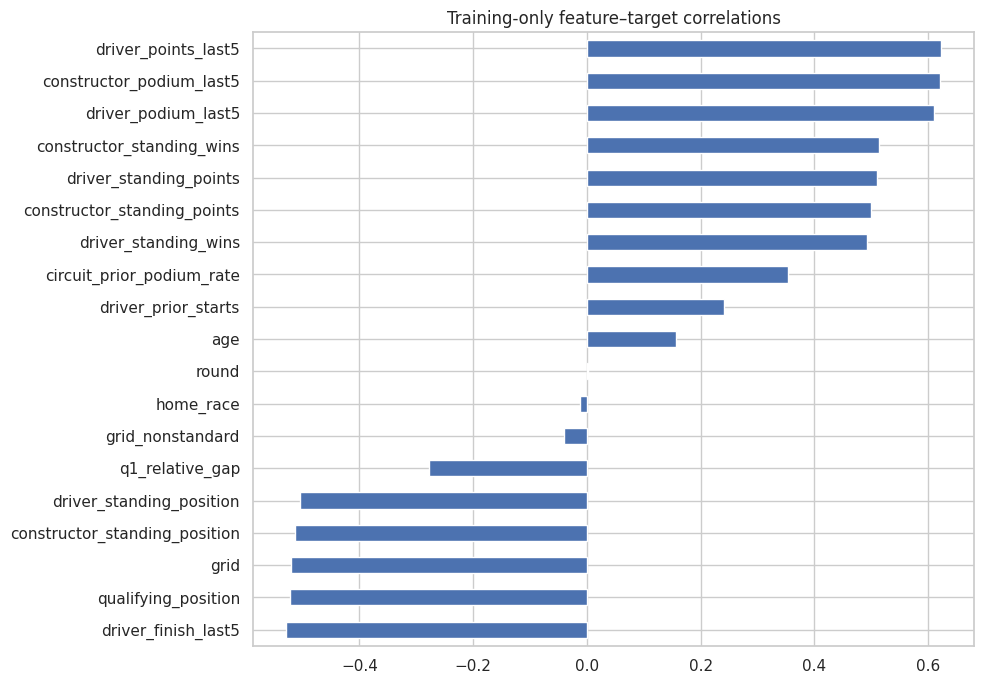

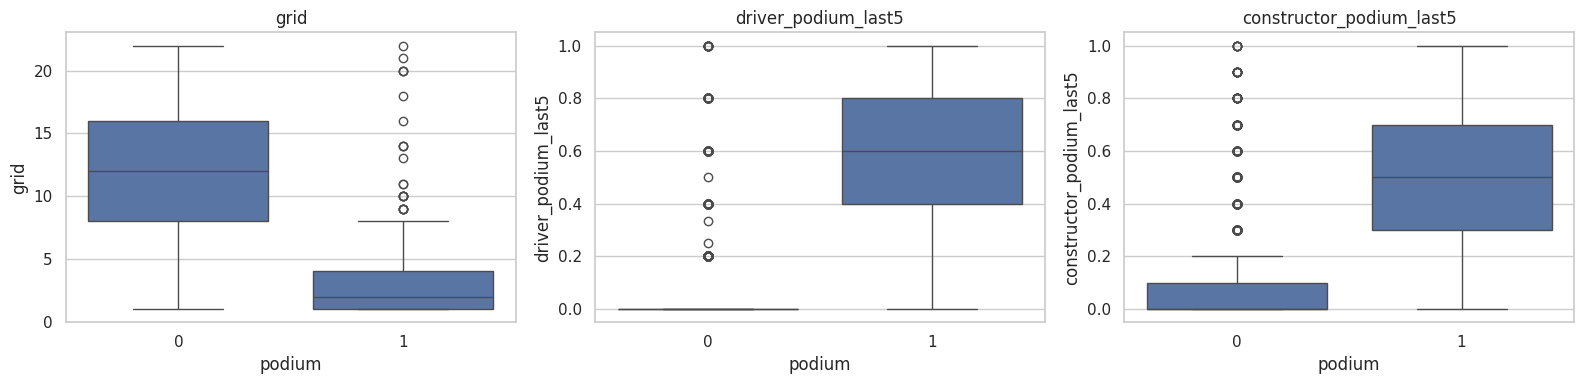

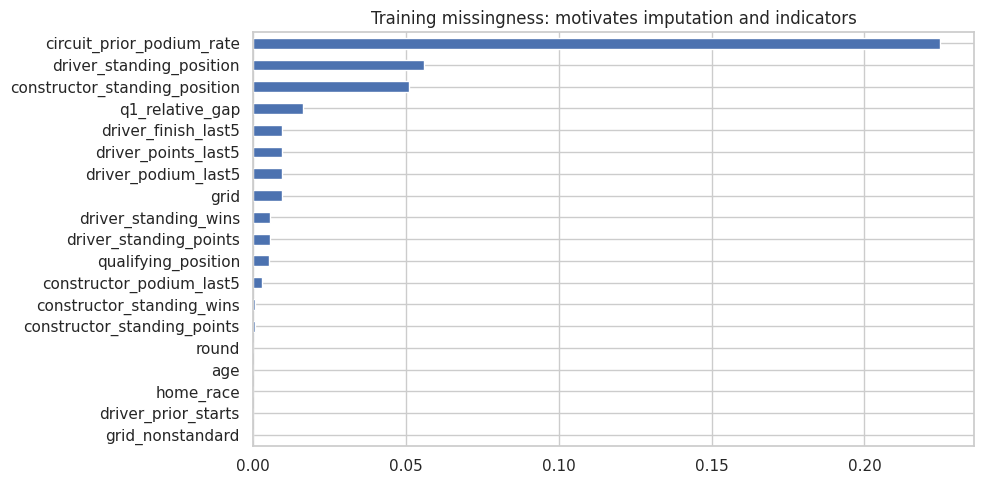

,group,features,justification
0,grid,"grid, grid_nonstandard",Actual pre-start rank and non-standard start f...
1,qualifying,"qualifying_position, q1_relative_gap",Qualifying rank and same-session Q1 gap descri...
2,driver_form,"driver_podium_last5, driver_finish_last5, driv...",Previous five recorded entries summarize recen...
3,constructor_form,constructor_podium_last5,Previous five race-level team outcomes summari...
4,standings,"driver_standing_points, driver_standing_positi...",Strictly previous same-season snapshots descri...
5,circuit_history,circuit_prior_podium_rate,Only prior appearances measure driver–circuit ...
6,context,"age, home_race, round","Age, round, and home indicator are known befor..."
7,identity,"driverId_category, constructorId_category, cir...",One-hot driver/team/circuit identities can lea...


### Feature selection evidence
Training-only correlations and box plots above test the competitiveness/form hypotheses. The strongest absolute numeric correlations are driver_points_last5 (+0.623), constructor_podium_last5 (+0.621), driver_podium_last5 (+0.610), driver_finish_last5 (-0.529), qualifying_position (-0.521). These coefficients retain their signs; features are ranked by absolute magnitude. All groups are retained initially; validation ablations below measure their incremental contribution. Test data were not used to choose the features.

In [151]:
correlations=train[NUM+['podium']].corr(numeric_only=True)['podium'].drop('podium').sort_values()
plt.figure(figsize=(10,7)); correlations.plot.barh(); plt.title('Training-only feature–target correlations')
savefig('feature_evidence_correlations')
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,col in zip(axes,['grid','driver_podium_last5','constructor_podium_last5']):
    sns.boxplot(data=train,x='podium',y=col,ax=ax); ax.set_title(col)
savefig('feature_evidence_distributions')
plt.figure(figsize=(10,5)); X_train[NUM].isna().mean().sort_values().plot.barh()
plt.title('Training missingness: motivates imputation and indicators'); savefig('feature_missingness')
feature_reasons={
 'grid':'Actual pre-start rank and non-standard start flag describe track position.',
 'qualifying':'Qualifying rank and same-session Q1 gap describe single-lap competitiveness; Q1 is comparable within a race.',
 'driver_form':'Previous five recorded entries summarize recent outcomes; driver_prior_starts is a historical feature name counting prior entries, including non-starters.',
 'constructor_form':'Previous five race-level team outcomes summarize current competitiveness without teammate leakage.',
 'standings':'Strictly previous same-season snapshots describe championship form, without current-race points.',
 'circuit_history':'Only prior appearances measure driver–circuit experience; missing for first visits.',
 'context':'Age, round, and home indicator are known before the race; weak correlations do not establish causal effects.',
 'identity':'One-hot driver/team/circuit identities can learn stable differences; unseen categories are handled safely.'}
feature_dictionary=pd.DataFrame([{'group':g,'features':', '.join(fs),'justification':feature_reasons[g]}
 for g,fs in feature_groups.items()])
display(feature_dictionary); feature_dictionary.to_csv(OUT/'feature_dictionary.csv',index=False)
finding('Feature selection evidence', 'Training-only correlations and box plots above test the competitiveness/form '
 'hypotheses. The strongest absolute numeric correlations are '+', '.join(
 f'{k} ({v:+.3f})' for k,v in correlations.loc[correlations.abs().sort_values(ascending=False).head(5).index].items())+
 '. These coefficients retain their signs; features are ranked by absolute magnitude. All groups are retained initially; validation ablations below '
 'measure their incremental contribution. Test data were not used to choose the features.')


## 7. Train-only preprocessing
Numerics: stable median imputation (zero only if a training column has no observations), missing indicators, and standard scaling. Categoricals: train-fitted one-hot encoding with unseen categories ignored. Every model receives the same rows and original features. Missing flags are deterministic transformations, not new future information. Fitted preprocessing is packaged with each model.

Experiments compare valid orders with 1st/99th-percentile clipping: **clip → impute → scale** versus **impute → clip → scale**, plus the baseline **impute → scale**. Quantiles/medians/scales are fitted only on training; imputed mass can change clipping quantiles. An unchanged score is a valid finding, not forced improvement.

In [152]:
%%writefile f1_preprocessing.py

import numpy as np

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler


class NumericProcessor(BaseEstimator, TransformerMixin):
    def __init__(self, order='impute_scale'):
        self.order = order

    def fit(self, X, y=None):
        a = np.asarray(X, dtype=float)
        a = np.where(np.isfinite(a), a, np.nan)

        # Preserve all-missing columns consistently across sklearn versions.
        self.median_ = np.array([
            np.median(c[np.isfinite(c)])
            if np.isfinite(c).any()
            else 0.
            for c in a.T
        ])

        if self.order == 'clip_impute_scale':

            bounds = np.array([
                np.quantile(
                    c[np.isfinite(c)],
                    [.01, .99]
                )
                if np.isfinite(c).any()
                else [0., 0.]
                for c in a.T
            ])

            self.low_, self.high_ = (
                bounds[:, 0],
                bounds[:, 1]
            )

            clipped = np.clip(
                a,
                self.low_,
                self.high_
            )

            self.median_ = np.array([
                np.median(c[np.isfinite(c)])
                if np.isfinite(c).any()
                else 0.
                for c in clipped.T
            ])

        elif self.order == 'impute_clip_scale':

            imputed = np.where(
                np.isnan(a),
                self.median_,
                a
            )

            self.low_, self.high_ = np.quantile(
                imputed,
                [.01, .99],
                axis=0
            )

        else:

            self.low_ = np.full(
                a.shape[1],
                -np.inf
            )

            self.high_ = np.full(
                a.shape[1],
                np.inf
            )

        self.scaler_ = StandardScaler().fit(
            self._values(a)
        )

        return self

    def _values(self, a):

        if self.order == 'clip_impute_scale':

            a = np.clip(
                a,
                self.low_,
                self.high_
            )

            return np.where(
                np.isnan(a),
                self.median_,
                a
            )

        return np.clip(
            np.where(
                np.isnan(a),
                self.median_,
                a
            ),
            self.low_,
            self.high_
        )

    def transform(self, X):

        a = np.asarray(
            X,
            dtype=float
        )

        a = np.where(
            np.isfinite(a),
            a,
            np.nan
        )

        return np.hstack([
            self.scaler_.transform(
                self._values(a)
            ),
            np.isnan(a).astype(float)
        ])

    def get_feature_names_out(
        self,
        input_features=None
    ):

        names = (
            list(input_features)
            if input_features is not None
            else [
                f'x{i}'
                for i in range(
                    len(self.median_)
                )
            ]
        )

        return np.array(
            names
            + [
                s + '_missing'
                for s in names
            ],
            dtype=object
        )

Overwriting f1_preprocessing.py


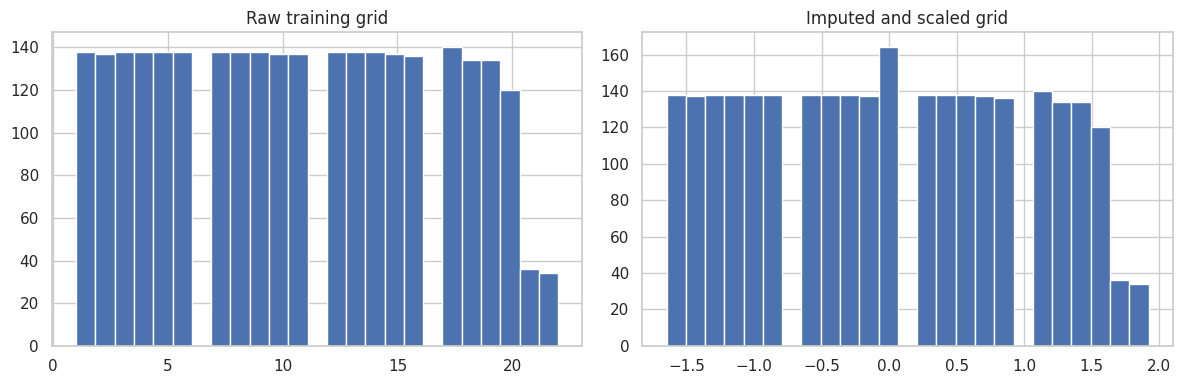

Encoded feature dimensions: 130


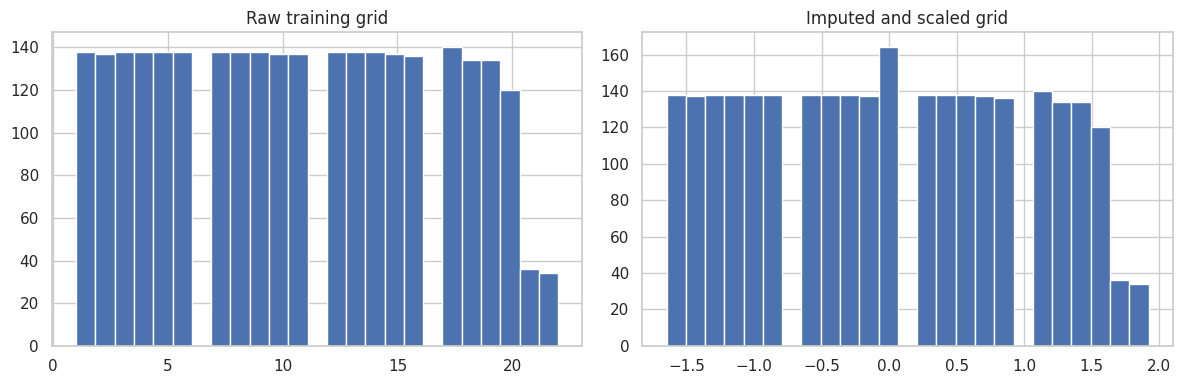

Encoded feature dimensions: 130


In [153]:
from f1_preprocessing import NumericProcessor


def make_preprocessor(features=FEATURES, order='impute_scale'):
    nums = [c for c in features if c in NUM]
    cats = [c for c in features if c in CAT]

    kwargs = {
        'handle_unknown': 'ignore',
        'dtype': np.float64
    }

    kwargs[
        'sparse_output'
        if 'sparse_output' in inspect.signature(
            OneHotEncoder
        ).parameters
        else 'sparse'
    ] = False

    transformers = []

    if nums:
        transformers.append(
            (
                'num',
                NumericProcessor(order),
                nums
            )
        )

    if cats:
        transformers.append(
            (
                'cat',
                OneHotEncoder(**kwargs),
                cats
            )
        )

    return ColumnTransformer(
        transformers,
        remainder='drop',
        sparse_threshold=0
    )


preprocessing_preview = (
    make_preprocessor()
    .fit(X_train)
)

transformed = (
    preprocessing_preview
    .transform(X_train)
)

assert np.isfinite(
    transformed
).all()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].hist(
    X_train.grid.dropna(),
    bins=25
)

axes[0].set_title(
    'Raw training grid'
)

axes[1].hist(
    transformed[:, NUM.index('grid')],
    bins=25
)

axes[1].set_title(
    'Imputed and scaled grid'
)

savefig(
    'preprocessing_effect'
)

print(
    'Encoded feature dimensions:',
    transformed.shape[1]
)

## 8. Three model families and validation-only selection
**Baseline:** logistic regression, simple regularized linear log-odds. **Random forest:** captures interactions, with depth/leaf limits to reduce overfitting. **Shallow neural network:** a 32 → 16 ReLU MLP; Adam, L2 regularization, and external chronological-validation early stopping. Logistic regression and forest test two settings each. NN epochs are selected using validation PR-AUC; weights are restored to the best epoch.

Primary metric = PR-AUC / average precision (AP), informative for the rare podium class. We also report trapezoidal PR-AUC to make the convention explicit. Secondary metric = F1 with a **validation-selected threshold**; ROC-AUC measures overall ranking. Precision and recall are reported as well, addressing the brief's inconsistent mention of “five metrics.” Test scores never select settings, thresholds, or the winner.

Limitations: logistic regression may miss nonlinear interactions; forests can overfit identities and season patterns; the NN requires scaling/regularization and can overfit the limited tabular sample. The comparison tests whether extra complexity improves on the statistical baseline.

In [154]:
def metric_values(y,p,threshold):
    pred=(np.asarray(p)>=threshold).astype(int)
    precision,recall,_=precision_recall_curve(y,p)
    return {'ROC_AUC':roc_auc_score(y,p),'PR_AUC_AP':average_precision_score(y,p),
     'PR_AUC_trapezoid':auc(recall,precision),'F1':f1_score(y,pred,zero_division=0),
     'Precision':precision_score(y,pred,zero_division=0),'Recall':recall_score(y,pred,zero_division=0)}
def choose_threshold(y,p):
    precision,recall,thresholds=precision_recall_curve(y,p)
    scores=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    return float(thresholds[np.argmax(scores)]) if len(thresholds) else .5
models={}; tuning_rows=[]


In [155]:
# Attempt 1: statistical baseline, two regularization settings.
lr_candidates=[]
for C in [.1,1.]:
    pipe=Pipeline([('preprocess',make_preprocessor()),
        ('model',LogisticRegression(C=C,max_iter=2000,random_state=SEED))])
    pipe.fit(X_train,y_train)
    score=average_precision_score(y_valid,pipe.predict_proba(X_valid)[:,1])
    tuning_rows.append({'family':'Logistic regression','setting':f'C={C}','validation_AP':score})
    lr_candidates.append((score,pipe))
models['Logistic regression']=max(lr_candidates,key=lambda pair:pair[0])[1]
display(pd.DataFrame(tuning_rows))


,family,setting,validation_AP
0,Logistic regression,C=0.1,0.715855
1,Logistic regression,C=1.0,0.712804


In [156]:
# Attempt 2: nonlinear statistical model, two leaf sizes.
rf_candidates=[]
for leaf in [3,8]:
    pipe=Pipeline([('preprocess',make_preprocessor()),
        ('model',RandomForestClassifier(n_estimators=160,max_depth=12,min_samples_leaf=leaf,
             max_features='sqrt',n_jobs=-1,random_state=SEED))])
    pipe.fit(X_train,y_train)
    score=average_precision_score(y_valid,pipe.predict_proba(X_valid)[:,1])
    tuning_rows.append({'family':'Random forest','setting':f'depth=12, leaf={leaf}','validation_AP':score})
    rf_candidates.append((score,pipe))
models['Random forest']=max(rf_candidates,key=lambda pair:pair[0])[1]
display(pd.DataFrame(tuning_rows)); pd.DataFrame(tuning_rows).to_csv(OUT/'hyperparameter_trials.csv',index=False)


,family,setting,validation_AP
0,Logistic regression,C=0.1,0.715855
1,Logistic regression,C=1.0,0.712804
2,Random forest,"depth=12, leaf=3",0.701925
3,Random forest,"depth=12, leaf=8",0.717434


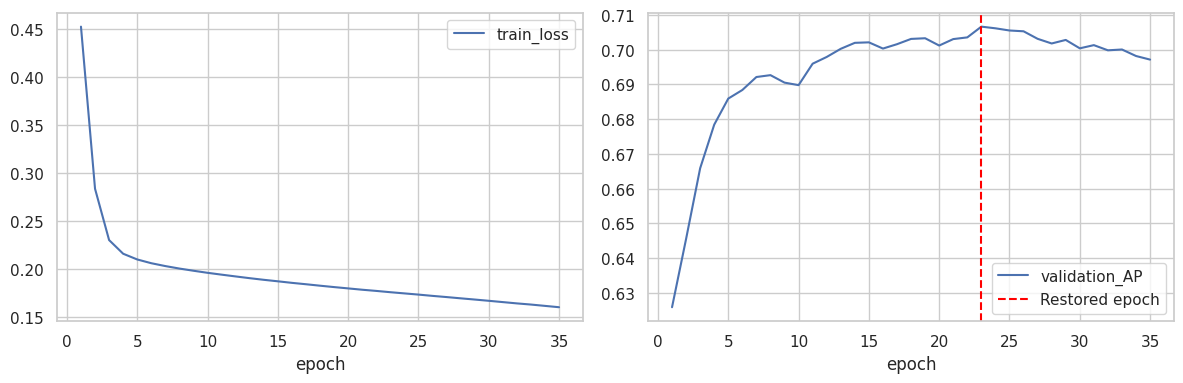

Restored NN epoch: 23


In [157]:
# Attempt 3: shallow NN with explicit chronological validation early stopping.
nn_pre=make_preprocessor().fit(X_train)
A=nn_pre.transform(X_train); B=nn_pre.transform(X_valid)
nn=MLPClassifier(hidden_layer_sizes=(32,16),activation='relu',solver='adam',alpha=.01,
    batch_size=min(128,len(A)),learning_rate_init=.001,random_state=SEED,shuffle=True)
best_nn=None; best_ap=-np.inf; stale=0; nn_history=[]
for epoch in range(1,101):
    nn.partial_fit(A,y_train.to_numpy(),classes=np.array([0,1]))
    val_ap=average_precision_score(y_valid,nn.predict_proba(B)[:,1])
    nn_history.append({'epoch':epoch,'train_loss':nn.loss_,'validation_AP':val_ap})
    if val_ap>best_ap+1e-5:
        best_ap=val_ap; best_nn=copy.deepcopy(nn); best_epoch=epoch; stale=0
    else: stale+=1
    if stale>=12: break
models['Shallow neural network']=Pipeline([('preprocess',nn_pre),('model',best_nn)])
nn_history=pd.DataFrame(nn_history); nn_history.to_csv(OUT/'nn_training_history.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4))
nn_history.plot(x='epoch',y='train_loss',ax=axes[0]); nn_history.plot(x='epoch',y='validation_AP',ax=axes[1])
axes[1].axvline(best_epoch,color='red',ls='--',label='Restored epoch'); axes[1].legend()
savefig('neural_network_learning_curve')
print('Restored NN epoch:',best_epoch)


In [158]:
thresholds={name:choose_threshold(y_valid,model.predict_proba(X_valid)[:,1]) for name,model in models.items()}
validation_scores={name:average_precision_score(y_valid,m.predict_proba(X_valid)[:,1]) for name,m in models.items()}
winner_name=max(validation_scores,key=validation_scores.get)
winner=models[winner_name]
# Winner and thresholds are now frozen before the test evaluation.
comparison=[]; predictions={}
for name,model in models.items():
    for split,X,y in [('Train',X_train,y_train),('Validation',X_valid,y_valid),('Test',X_test,y_test)]:
        p=model.predict_proba(X)[:,1]; predictions[(name,split)]=p
        comparison.append({'model':name,'split':split,'threshold':thresholds[name],**metric_values(y,p,thresholds[name])})
comparison=pd.DataFrame(comparison)
display(comparison); comparison.to_csv(OUT/'model_comparison.csv',index=False)
finding('Model comparison', f'The validation-selected model is {winner_name}, '
 f'with validation AP {validation_scores[winner_name]:.4f} and threshold {thresholds[winner_name]:.4f}. '
 'The training/validation/test table gives ROC-AUC, both PR-AUC conventions, F1, precision and recall. '
 'NN epoch selection and model selection use the same validation seasons, so selection optimism remains; '
 'the later test seasons provide the final independent performance estimate.')


,model,split,threshold,ROC_AUC,PR_AUC_AP,PR_AUC_trapezoid,F1,Precision,Recall
0,Logistic regression,Train,0.264878,0.946920,0.734246,0.733037,0.704453,0.606272,0.840580
1,Logistic regression,Validation,0.264878,0.942878,0.715855,0.713777,0.708861,0.608696,0.848485
2,Logistic regression,Test,0.264878,0.922600,0.691760,0.690325,0.652568,0.559585,0.782609
3,Random forest,Train,0.396303,0.968672,0.843585,0.843374,0.763761,0.727074,0.804348
4,Random forest,Validation,0.396303,0.940630,0.717434,0.715949,0.704626,0.664430,0.750000
5,Random forest,Test,0.396303,0.929392,0.696707,0.694952,0.655172,0.625000,0.688406
6,Shallow neural network,Train,0.298077,0.963442,0.805388,0.805020,0.742798,0.646953,0.871981
7,Shallow neural network,Validation,0.298077,0.941703,0.706651,0.704775,0.713826,0.620112,0.840909
8,Shallow neural network,Test,0.298077,0.918341,0.649387,0.647290,0.629412,0.529703,0.775362


### Model comparison
The validation-selected model is Random forest, with validation AP 0.7174 and threshold 0.3963. The training/validation/test table gives ROC-AUC, both PR-AUC conventions, F1, precision and recall. NN epoch selection and model selection use the same validation seasons, so selection optimism remains; the later test seasons provide the final independent performance estimate.

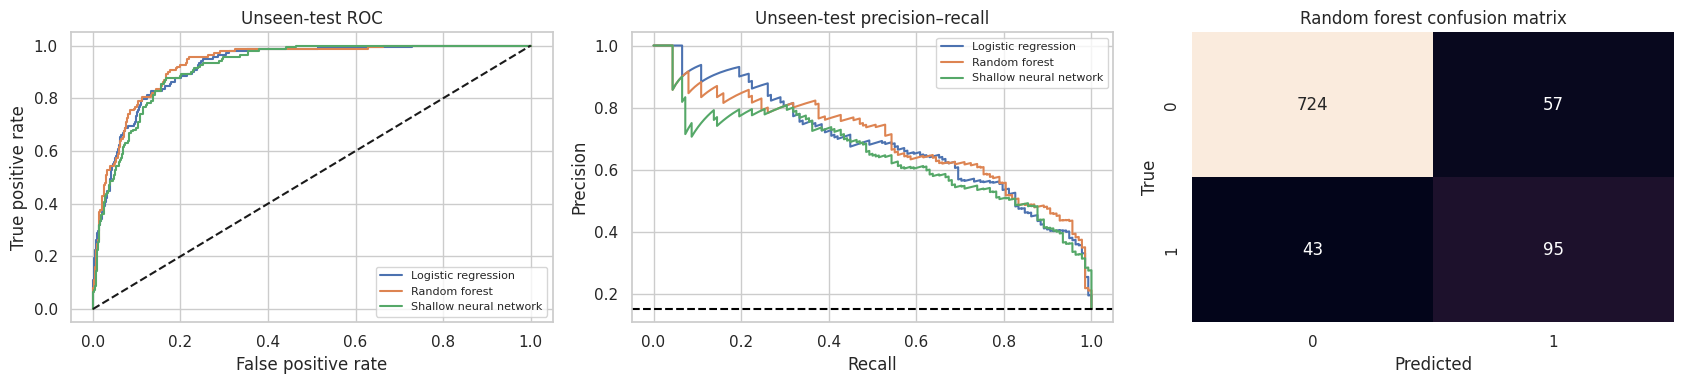

In [159]:
fig,axes=plt.subplots(1,3,figsize=(17,4))
for name in models:
    p=predictions[(name,'Test')]
    fpr,tpr,_=roc_curve(y_test,p); axes[0].plot(fpr,tpr,label=name)
    prec,rec,_=precision_recall_curve(y_test,p); axes[1].plot(rec,prec,label=name)
axes[0].plot([0,1],[0,1],'k--'); axes[0].set_title('Unseen-test ROC'); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[1].axhline(y_test.mean(),ls='--',color='black'); axes[1].set_title('Unseen-test precision–recall'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
cm=confusion_matrix(y_test,predictions[(winner_name,'Test')]>=thresholds[winner_name])
sns.heatmap(cm,annot=True,fmt='d',cbar=False,ax=axes[2]); axes[2].set_title(winner_name+' confusion matrix'); axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('True')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
savefig('test_model_evaluation')


## 9. Feature-group ablation
Controlled logistic-regression ablations remove each group once. C is frozen from the selected baseline; preprocessing is refitted on the same training rows. Each variant's threshold is selected on validation only. Report validation AP and F1 differences relative to the full baseline. Test data are excluded. A negative AP drop means removing a group helped; importance is conditional on the other groups and this model family.

,removed_group,ROC_AUC,PR_AUC_AP,PR_AUC_trapezoid,F1,Precision,Recall,AP_drop
0,None (full baseline),0.942878,0.715855,0.713777,0.708861,0.608696,0.848485,0.000000
1,grid,0.940326,0.706111,0.703837,0.702875,0.607735,0.833333,0.009743
2,qualifying,0.939728,0.707737,0.705885,0.708861,0.608696,0.848485,0.008118
3,driver_form,0.943617,0.721526,0.719411,0.705167,0.588832,0.878788,-0.005672
4,constructor_form,0.942989,0.719988,0.718232,0.710345,0.651899,0.780303,-0.004133
5,standings,0.940427,0.707683,0.705673,0.712871,0.631579,0.818182,0.008172
6,circuit_history,0.942736,0.717684,0.715658,0.708464,0.604278,0.856061,-0.001829
7,context,0.941966,0.719128,0.717430,0.714286,0.648148,0.795455,-0.003273
8,identity,0.941106,0.705517,0.703104,0.716049,0.604167,0.878788,0.010338


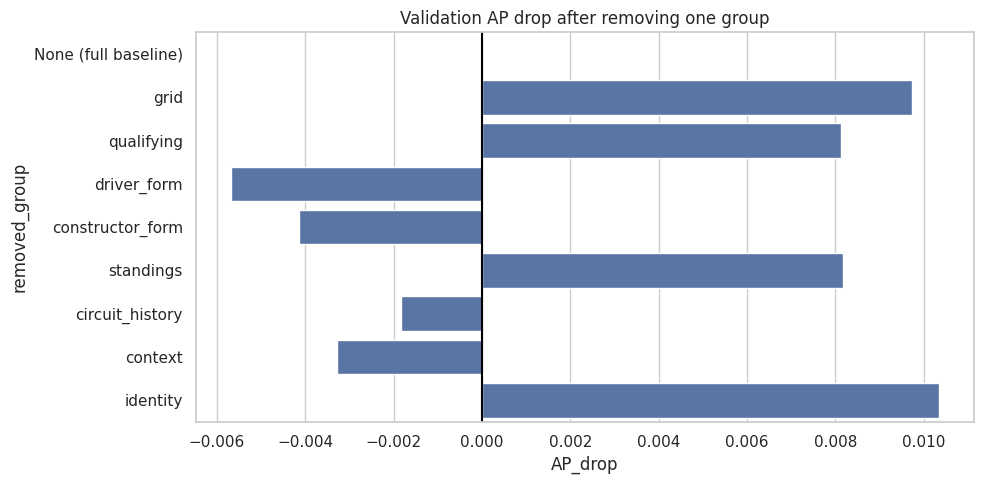

### Ablation interpretation
Removing identity produces the largest validation AP drop (+0.0103) for logistic regression. All groups and negative/zero changes are shown. Redundant grid/qualifying and form/standings features can mask individual group contributions; this experiment does not claim the same ordering for every model.

In [160]:
base_model=models['Logistic regression']; chosen_C=base_model.named_steps['model'].C
base_p=base_model.predict_proba(X_valid)[:,1]
base_stats=metric_values(y_valid,base_p,thresholds['Logistic regression'])
ablation=[{'removed_group':'None (full baseline)',**base_stats,'AP_drop':0.}]
for group,removed in feature_groups.items():
    fs=[c for c in FEATURES if c not in removed]
    pipe=Pipeline([('preprocess',make_preprocessor(fs)),
        ('model',LogisticRegression(C=chosen_C,max_iter=2000,random_state=SEED))])
    pipe.fit(X_train[fs],y_train)
    p=pipe.predict_proba(X_valid[fs])[:,1]
    stats=metric_values(y_valid,p,choose_threshold(y_valid,p))
    ablation.append({'removed_group':group,**stats,'AP_drop':base_stats['PR_AUC_AP']-stats['PR_AUC_AP']})
ablation=pd.DataFrame(ablation); display(ablation)
ablation.to_csv(OUT/'feature_group_ablation.csv',index=False)
plt.figure(figsize=(10,5)); sns.barplot(data=ablation,x='AP_drop',y='removed_group')
plt.axvline(0,color='black'); plt.title('Validation AP drop after removing one group'); savefig('feature_group_ablation')
strong=ablation[ablation.removed_group.ne('None (full baseline)')].sort_values('AP_drop',ascending=False).iloc[0]
finding('Ablation interpretation', f"Removing {strong.removed_group} produces the largest validation AP drop "
 f"({strong.AP_drop:+.4f}) for logistic regression. All groups and negative/zero changes are shown. "
 'Redundant grid/qualifying and form/standings features can mask individual group contributions; '
 'this experiment does not claim the same ordering for every model.')


## 10. Preprocessing-order experiments
Keep logistic-regression C, rows and feature set fixed; refit only the preprocessing order. Validation AP is the comparison criterion. These experiments document sensitivity; they do not retrospectively change the frozen three-model test comparison.

The frozen final model retains impute → scale. These logistic-regression trials show small validation differences and do not establish a better preprocessing choice for the selected random forest.

,order,ROC_AUC,PR_AUC_AP,PR_AUC_trapezoid,F1,Precision,Recall,AP_change_from_baseline
0,impute_scale,0.942878,0.715855,0.713777,0.708861,0.608696,0.848485,0.000000
1,clip_impute_scale,0.942422,0.719908,0.718169,0.708861,0.608696,0.848485,0.004054
2,impute_clip_scale,0.942422,0.719490,0.717735,0.708861,0.608696,0.848485,0.003635


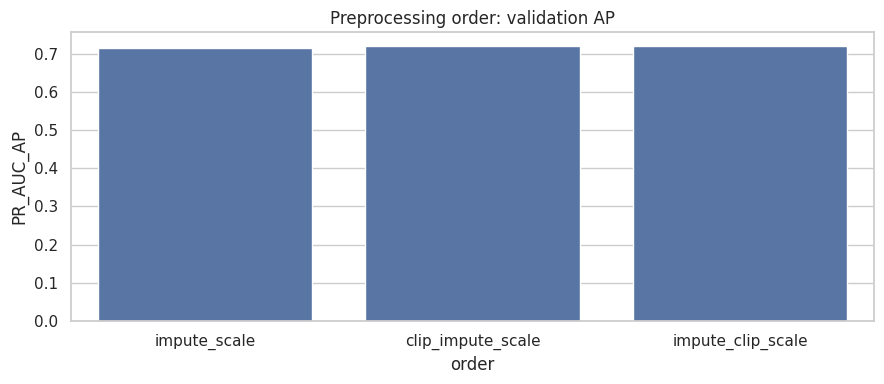

### Preprocessing sensitivity
impute_scale: AP 0.7159 (change +0.0000); clip_impute_scale: AP 0.7199 (change +0.0041); impute_clip_scale: AP 0.7195 (change +0.0036). Orders are legitimate and train-fitted. Similar scores imply these clipping/order choices add little here; different scores reflect changed distributions and are not automatically transferable to other seasons.

In [161]:
preprocess_experiments=[]
for order in ['impute_scale','clip_impute_scale','impute_clip_scale']:
    pipe=Pipeline([('preprocess',make_preprocessor(order=order)),
                   ('model',LogisticRegression(C=chosen_C,max_iter=2000,random_state=SEED))])
    pipe.fit(X_train,y_train)
    p=pipe.predict_proba(X_valid)[:,1]
    preprocess_experiments.append({'order':order,**metric_values(y_valid,p,choose_threshold(y_valid,p))})
preprocess_experiments=pd.DataFrame(preprocess_experiments)
preprocess_experiments['AP_change_from_baseline']=preprocess_experiments.PR_AUC_AP-preprocess_experiments.iloc[0].PR_AUC_AP
display(preprocess_experiments); preprocess_experiments.to_csv(OUT/'preprocessing_orders.csv',index=False)
plt.figure(figsize=(9,4)); sns.barplot(data=preprocess_experiments,x='order',y='PR_AUC_AP')
plt.title('Preprocessing order: validation AP'); savefig('preprocessing_order_comparison')
finding('Preprocessing sensitivity', '; '.join(f'{r.order}: AP {r.PR_AUC_AP:.4f} '
 f'(change {r.AP_change_from_baseline:+.4f})' for r in preprocess_experiments.itertuples())+
 '. Orders are legitimate and train-fitted. Similar scores imply these clipping/order choices add little here; '
 'different scores reflect changed distributions and are not automatically transferable to other seasons.')


## 11. Global explanation: permutation importance
On a fixed validation sample, shuffle one original feature at a time and measure the AP decrease. Repeats show sampling variability. Correlated predictors can substitute for each other, understating their separate importance. Permutation importance explains reliance, **not causal effects**.

,feature,AP_decrease,std
0,grid,0.047338,0.018897
2,qualifying_position,0.040157,0.028485
19,driverId_category,0.010484,0.005889
20,constructorId_category,0.009306,0.009202
15,circuit_prior_podium_rate,0.008443,0.003778
8,constructor_podium_last5,0.007701,0.008687
10,driver_standing_position,0.006658,0.009930
6,driver_points_last5,0.003927,0.015991
21,circuitId_category,0.002098,0.001812
1,grid_nonstandard,0.000000,0.000000


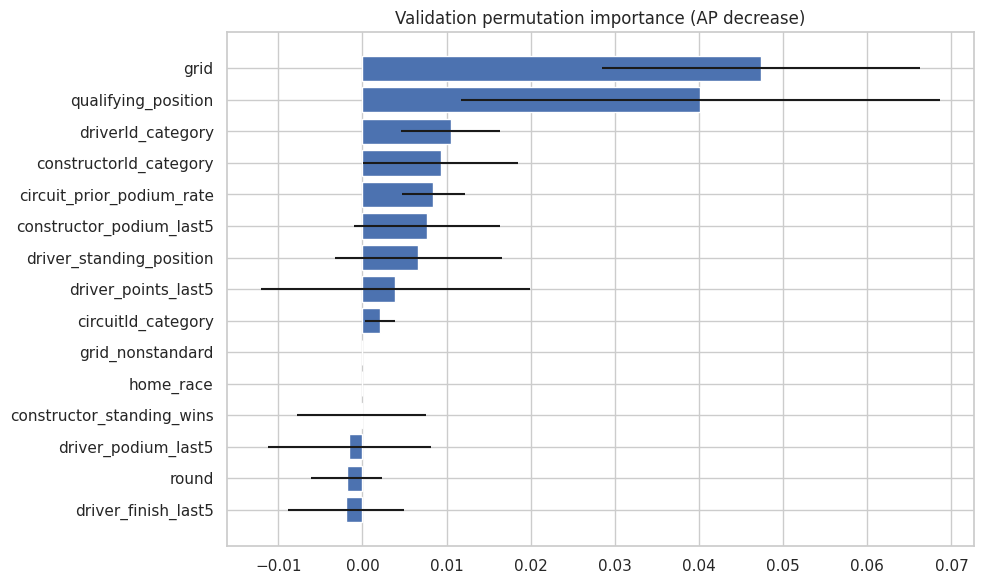

### Permutation interpretation
Largest validation AP decreases: grid (+0.0473), qualifying_position (+0.0402), driverId_category (+0.0105), constructorId_category (+0.0093), circuit_prior_podium_rate (+0.0084). Positive values mean the model relied on these features for ranking; small/negative values can reflect noise or redundant predictors. These are not causal estimates.

In [162]:
xai_sample=X_valid.sample(n=min(300,len(X_valid)),random_state=SEED)
xai_labels=y_valid.loc[xai_sample.index]
permutation=permutation_importance(winner,xai_sample,xai_labels,scoring='average_precision',
                                  n_repeats=5,random_state=SEED,n_jobs=1)
permutation_table=pd.DataFrame({'feature':FEATURES,'AP_decrease':permutation.importances_mean,
 'std':permutation.importances_std}).sort_values('AP_decrease',ascending=False)
display(permutation_table); permutation_table.to_csv(OUT/'permutation_importance.csv',index=False)
plot=permutation_table.head(15).sort_values('AP_decrease')
plt.figure(figsize=(10,6)); plt.barh(plot.feature,plot.AP_decrease,xerr=plot['std'])
plt.title('Validation permutation importance (AP decrease)'); savefig('permutation_importance')
finding('Permutation interpretation', 'Largest validation AP decreases: '+', '.join(
 f'{r.feature} ({r.AP_decrease:+.4f})' for r in permutation_table.head(5).itertuples())+
 '. Positive values mean the model relied on these features for ranking; small/negative values can reflect '
 'noise or redundant predictors. These are not causal estimates.')


## 12. Global and local SHAP
Use the official `shap.PermutationExplainer` on the complete fitted pipeline. Categories are reversibly coded for the numeric masker and decoded before prediction; codes are never treated as ordinal model inputs. A 40-row training background and 40 validation rows keep CPU cost manageable. Twelve permutation cycles estimate interventional Shapley contributions in probability units. Additivity is verified, and a second seed checks sampling sensitivity. Correlated-feature mixtures may be unrealistic; these explanations describe associations, not causes.


In [163]:
import importlib, subprocess, sys
for package in ['shap','lime']:
    try: importlib.import_module(package)
    except ImportError:
        subprocess.check_call([sys.executable,'-m','pip','install',package])
import shap
from lime.lime_tabular import LimeTabularExplainer
category_levels={c:sorted(set(X_train[c].astype(str)) | set(X_valid[c].astype(str))) for c in CAT}
def encode_original(frame):
    result=frame[FEATURES].copy()
    for c in CAT: result[c]=pd.Categorical(result[c].astype(str),categories=category_levels[c]).codes
    return result.to_numpy(dtype=float)
def decode_original(values):
    frame=pd.DataFrame(np.asarray(values),columns=FEATURES)
    for c in CAT:
        codes=np.rint(frame[c]).astype(int).to_numpy()
        frame[c]=[category_levels[c][v] if 0<=v<len(category_levels[c]) else 'unknown' for v in codes]
    return frame
def shap_predict(values):return winner.predict_proba(decode_original(values))[:,1]
background=X_train.sample(min(40,len(X_train)),random_state=SEED)
shap_rows=X_valid.sample(min(40,len(X_valid)),random_state=SEED).reset_index(drop=True)
explainer=shap.PermutationExplainer(shap_predict,shap.maskers.Independent(encode_original(background)),feature_names=FEATURES,seed=SEED)
shap_explanation=explainer(encode_original(shap_rows),max_evals=(2*len(FEATURES)+1)*12)
shap_values=shap_explanation.values; shap_bases=shap_explanation.base_values
shap_predictions=winner.predict_proba(shap_rows)[:,1]
assert np.allclose(shap_bases+shap_values.sum(axis=1),shap_predictions,atol=1e-6)
shap_table=pd.DataFrame({'feature':FEATURES,'mean_absolute_SHAP':np.abs(shap_values).mean(axis=0)}).sort_values('mean_absolute_SHAP',ascending=False)
display(shap_table); shap_table.to_csv(OUT/'global_shap.csv',index=False)
pd.DataFrame(shap_values,columns=FEATURES).to_csv(OUT/'row_shap_values.csv',index=False)


PermutationExplainer explainer: 41it [00:40,  1.27s/it]                        


,feature,mean_absolute_SHAP
0,grid,0.048326
2,qualifying_position,0.046800
6,driver_points_last5,0.024514
13,constructor_standing_position,0.020470
4,driver_podium_last5,0.018422
8,constructor_podium_last5,0.014489
20,constructorId_category,0.013424
10,driver_standing_position,0.013349
3,q1_relative_gap,0.011313
5,driver_finish_last5,0.011049


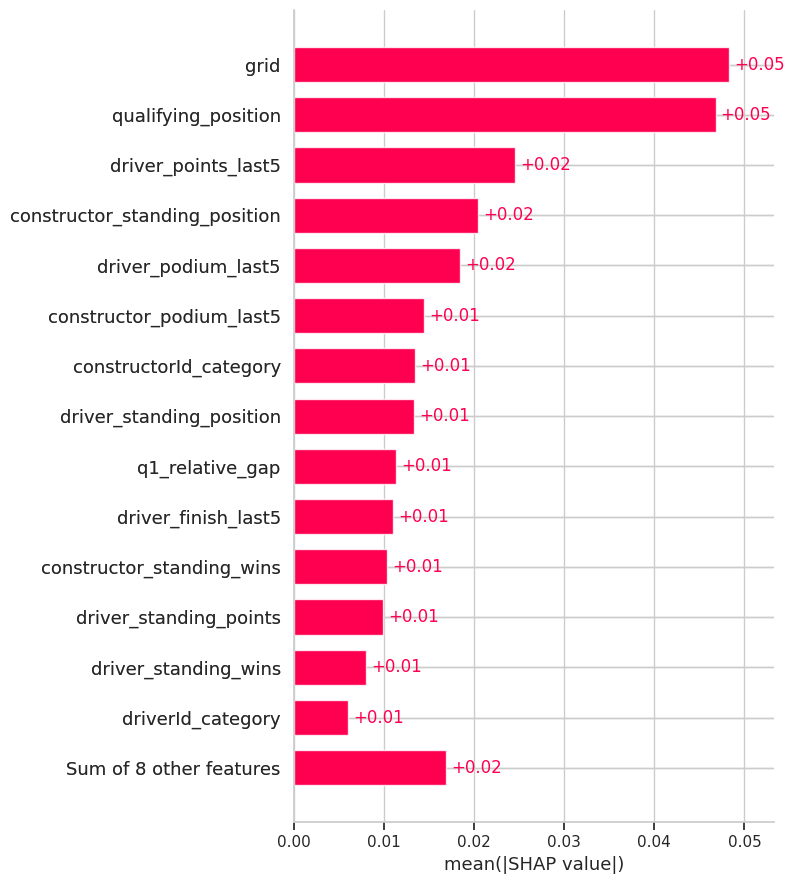

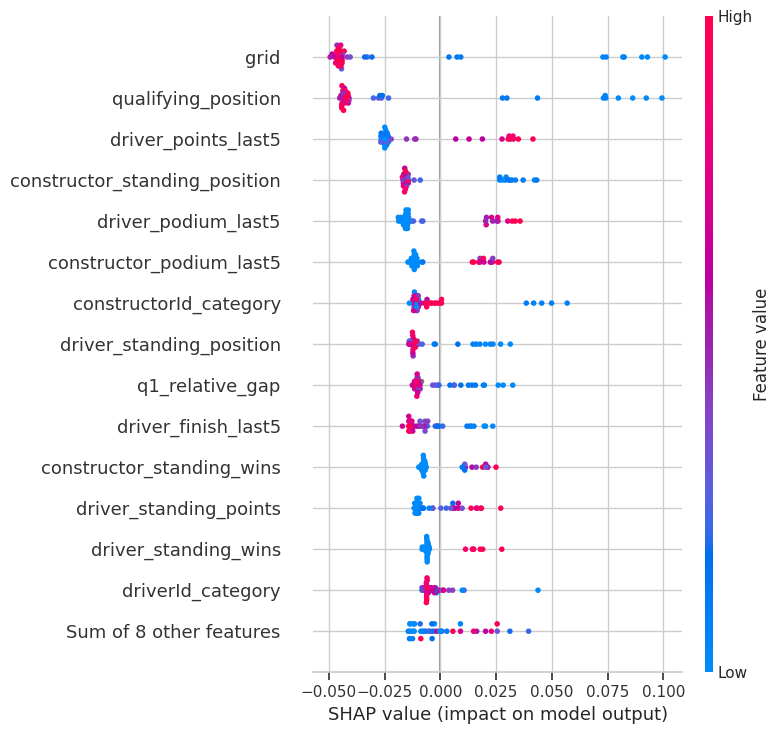

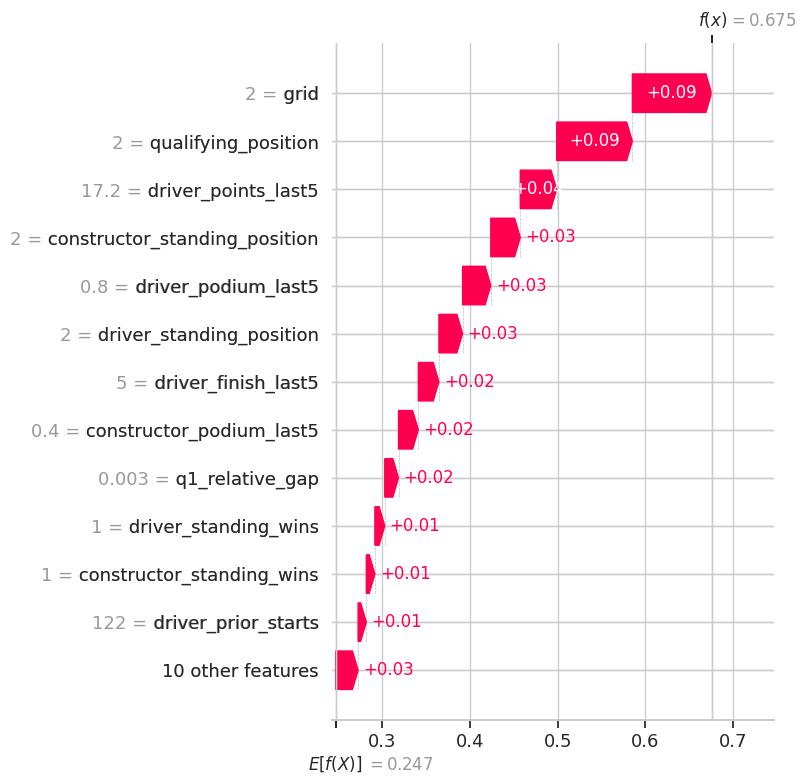

### SHAP interpretation
Top global attributions: grid, qualifying_position, driver_points_last5, constructor_standing_position, driver_podium_last5. Selected validation prediction: 0.6754; training-background probability: 0.2470. Additivity passed. Mean absolute difference with a second seed: 0.0009. Positive contributions raise predicted probability; negative contributions lower it. They are not causal effects. Category colors reflect arbitrary display codes, not an ordinal scale.

In [164]:
shap.plots.bar(shap_explanation,max_display=15,show=False); savefig('global_shap_bar')
shap.plots.beeswarm(shap_explanation,max_display=15,show=False); savefig('global_shap')
# Choose a complete validation row, if available, so the LIME example is easy to inspect.
complete_indices=np.flatnonzero(shap_rows[NUM].notna().all(axis=1))
local_index=int(complete_indices[np.argmax(shap_predictions[complete_indices])]) if len(complete_indices) else int(np.argmax(shap_predictions))
local_values=shap_values[local_index]
shap.plots.waterfall(shap_explanation[local_index],max_display=13,show=False); savefig('local_shap_waterfall')
second_explainer=shap.PermutationExplainer(shap_predict,shap.maskers.Independent(encode_original(background)),feature_names=FEATURES,seed=SEED+1)
second=second_explainer(encode_original(shap_rows.iloc[[local_index]]),max_evals=(2*len(FEATURES)+1)*12)
uncertainty=float(np.abs(second.values[0]-local_values).mean())
local_explanation=pd.DataFrame({'feature':FEATURES,'value':shap_rows.iloc[local_index].to_numpy(),'SHAP':local_values})
local_explanation.to_csv(OUT/'local_shap.csv',index=False)
finding('SHAP interpretation','Top global attributions: '+', '.join(shap_table.head(5).feature)+
 f'. Selected validation prediction: {shap_predictions[local_index]:.4f}; training-background probability: {shap_bases[local_index]:.4f}. '+
 f'Additivity passed. Mean absolute difference with a second seed: {uncertainty:.4f}. '+
 'Positive contributions raise predicted probability; negative contributions lower it. They are not causal effects. Category colors reflect arbitrary display codes, not an ordinal scale.')


## 13. Local LIME
Use the official `LimeTabularExplainer` around the same validation row. Numeric inputs use training medians and carry explicit missingness flags; categories and flags are declared categorical. The prediction wrapper reconstructs missing values and category strings, then calls the entire fitted pipeline. LIME discretizes numeric features into readable conditions. Report weighted neighborhood R², classifier probability and surrogate prediction. Fidelity is measured on the generated neighborhood, not independent data; correlated feature perturbations can be unrealistic.


,term,coefficient
0,qualifying_position <= 6.00,0.087960
1,grid <= 6.00,0.076898
2,driver_points_last5 > 7.80,0.052954
3,driver_podium_last5 > 0.20,0.043066
4,constructor_standing_position <= 3.00,0.041721
5,constructor_podium_last5 > 0.20,0.034251
6,driver_standing_points > 57.00,0.033684
7,driver_finish_last5 <= 7.40,0.029020
8,constructor_standing_wins > 0.00,0.026408
9,constructor_standing_wins_is_missing=observed,-0.023555


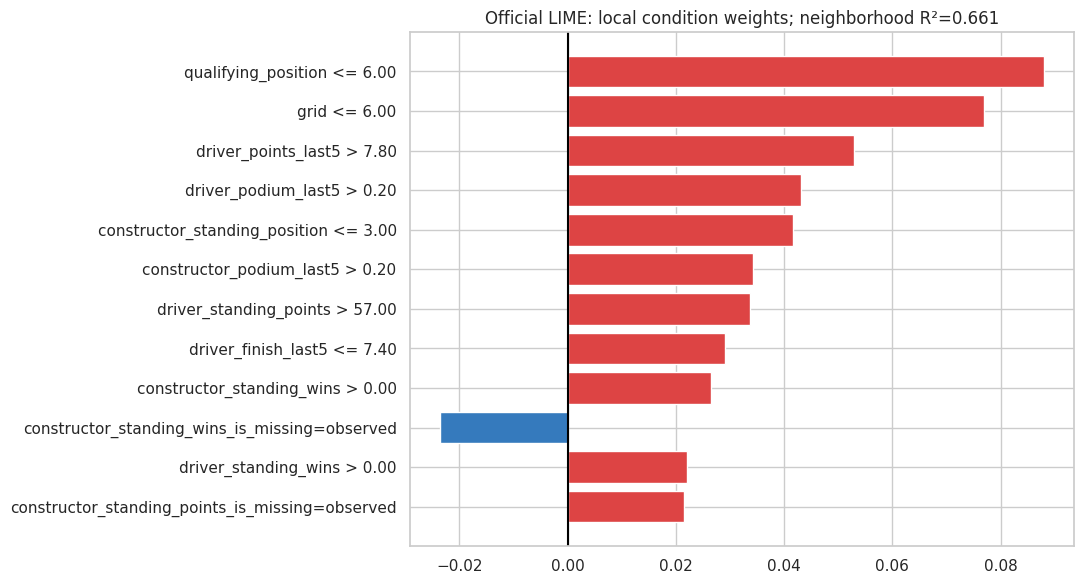

### Local surrogate fidelity
LIME weighted neighborhood R²=0.661; classifier probability=0.6754; surrogate prediction=0.4924. Positive conditions support the podium class locally; negative conditions oppose it. Low fidelity limits interpretation. These are local associations, not causal effects.

In [165]:
lime_features=FEATURES+[c+'_is_missing' for c in NUM]
lime_medians=X_train[NUM].median().fillna(0)
def encode_lime(frame):
    a=encode_original(frame)
    for c in NUM:
        j=FEATURES.index(c); a[:,j]=np.where(np.isfinite(a[:,j]),a[:,j],lime_medians[c])
    return np.column_stack([a,frame[NUM].isna().to_numpy(dtype=float)])
def lime_predict(values):
    values=np.asarray(values); frame=decode_original(values[:,:len(FEATURES)])
    for j,c in enumerate(NUM):frame.loc[values[:,len(FEATURES)+j]>=.5,c]=np.nan
    return winner.predict_proba(frame)
lime_categories=[FEATURES.index(c) for c in CAT]+list(range(len(FEATURES),len(lime_features)))
lime_names={FEATURES.index(c):category_levels[c] for c in CAT}
lime_names.update({j:['observed','missing'] for j in range(len(FEATURES),len(lime_features))})
lime_explainer=LimeTabularExplainer(encode_lime(X_train),feature_names=lime_features,
 class_names=['Not podium','Podium'],categorical_features=lime_categories,categorical_names=lime_names,
 mode='classification',random_state=SEED,discretize_continuous=True)
local_row=shap_rows.iloc[[local_index]]
lime_exp=lime_explainer.explain_instance(encode_lime(local_row)[0],lime_predict,num_features=12,num_samples=4000,labels=(1,))
fidelity=float(lime_exp.score)
lime_table=pd.DataFrame(lime_exp.as_list(label=1),columns=['term','coefficient'])
display(lime_table); lime_table.to_csv(OUT/'local_lime.csv',index=False)
plt.figure(figsize=(11,6)); subset=lime_table.iloc[::-1]
plt.barh(subset.term,subset.coefficient,color=np.where(subset.coefficient>=0,'#d44','#357abd'))
plt.axvline(0,color='black'); plt.title(f'Official LIME: local condition weights; neighborhood R²={fidelity:.3f}')
savefig('local_lime')
finding('Local surrogate fidelity',f'LIME weighted neighborhood R²={fidelity:.3f}; classifier probability={shap_predictions[local_index]:.4f}; surrogate prediction={float(lime_exp.local_pred[0]):.4f}. '+
 'Positive conditions support the podium class locally; negative conditions oppose it. Low fidelity limits interpretation. These are local associations, not causal effects.')


## 14. Inference: complete, partially missing, and unseen categories
Input = an engineered pre-race record using the feature dictionary. The caller must supply histories available at the prediction cutoff; this function does not fetch live F1 data. Missing keys/numeric values are handled by fitted training medians and flags. Unknown identity categories are supported. Outputs are independent driver probabilities; they are not constrained to sum to three podium places per race.

In [166]:
def predict_podium(record,model=winner,threshold=thresholds[winner_name]):
    if not isinstance(record,(dict,pd.Series)):
        raise TypeError('Supply a dict or pandas Series of pre-race feature values.')
    row={c:record.get(c,np.nan) for c in FEATURES}
    for c in CAT:
        value=row[c]
        if pd.isna(value): row[c]='unknown'
        elif isinstance(value,(int,float,np.integer,np.floating)):
            row[c]=str(int(value))
        else: row[c]=str(value)
    frame=pd.DataFrame([row],columns=FEATURES)
    for c in NUM:
        frame[c]=pd.to_numeric(frame[c],errors='coerce').replace([np.inf,-np.inf],np.nan)
    probability=float(model.predict_proba(frame)[0,1])
    return {'podium_probability':probability,'predicted_podium':bool(probability>=threshold),
            'threshold':float(threshold),'model':winner_name}
complete_candidates=X_valid.dropna()
# If no genuinely complete observed row exists, create a clearly labeled completed example
# using training medians. This is an input demonstration, not a claimed actual record.
if len(complete_candidates):
    complete_record=complete_candidates.iloc[0].to_dict(); complete_source='Complete observed validation record'
else:
    complete_record=X_valid.iloc[0].to_dict()
    for c in NUM:
        if pd.isna(complete_record[c]):
            complete_record[c]=float(X_train[c].median()) if X_train[c].notna().any() else 0.
    complete_source='Validation record completed with training medians for demonstration'
partial_record=complete_record.copy()
for c in ['qualifying_position','q1_relative_gap','driver_finish_last5','circuit_prior_podium_rate']:
    partial_record.pop(c,None)
partial_record['driverId_category']='unseen_driver'
inference_examples=pd.DataFrame([{'example':complete_source,**predict_podium(complete_record)},
    {'example':'Partially missing / unseen driver',**predict_podium(partial_record)}])
display(inference_examples); inference_examples.to_csv(OUT/'inference_examples.csv',index=False)
assert inference_examples.podium_probability.between(0,1).all()
assert 0<=predict_podium({})['podium_probability']<=1
with open(OUT/'model_bundle.pkl','wb') as f:
    pickle.dump({'model':winner,'model_name':winner_name,'features':FEATURES,
                 'numeric':NUM,'categorical':CAT,'threshold':thresholds[winner_name]},f)
# Check that the saved model can be loaded
# in a completely fresh Python process.

import subprocess
import sys

bundle_path = (
    OUT / 'model_bundle.pkl'
).resolve()

test_code = f"""
import pickle

with open(r'{bundle_path}', 'rb') as f:
    bundle = pickle.load(f)

print(
    'Fresh-process load OK:',
    bundle['model_name']
)
"""

result = subprocess.run(
    [
        sys.executable,
        '-c',
        test_code
    ],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)    
finding('Inference demonstration', 'Both complete and partially missing inputs produced finite probabilities. '
 'The second example removes qualifying/history values and uses an unseen driver category. '
 'Inputs require the same leakage-safe definitions as training; severely incomplete records may give unreliable probabilities.')


,example,podium_probability,predicted_podium,threshold,model
0,Complete observed validation record,0.848180,True,0.396303,Random forest
1,Partially missing / unseen driver,0.537961,True,0.396303,Random forest


Fresh-process load OK: Random forest



### Inference demonstration
Both complete and partially missing inputs produced finite probabilities. The second example removes qualifying/history values and uses an unseen driver category. Inputs require the same leakage-safe definitions as training; severely incomplete records may give unreliable probabilities.

## 15. Polished analytical report
This cell builds the submission PDF directly from the current results, explanations and saved figures. It uses Matplotlib, without ReportLab or internet installation. The generated `f1_outputs/F1_Analytical_Report.pdf` is the PDF to submit; no separately edited report is needed.


In [167]:
limitations = (
    'Historical qualifying coverage changes; 2024 can be incomplete depending on dataset version. '
    'The model uses 2014-2024 with sequentially updated histories, but regulations and constructors change. '
    'Shared-drive deduplication and retrospective entrant lists are source limitations. '
    'Nationality labels are stripped of leading and trailing whitespace before mapping. '
    'Dual-nationality labels are not forced into one country: Q2 excludes those rows, while the predictive '
    'model treats home_race as missing for them. Nationality remains only a proxy for home country. '
    'Failure labels are conservative and constructor renamings remain separate. '
    'Grid-stratified home comparisons retain driver/team/era confounding. '
    'Validation is reused for tuning, thresholds and early stopping, so its scores may be optimistic. '
    'Test seasons are not used for selection. '
    'Permutation importance, SHAP and local surrogates explain associations, not causes. '
    'Monte Carlo SHAP has sampling uncertainty and can create unrealistic correlated-feature combinations. '
    'Probabilities are independent across drivers and not guaranteed calibrated.'
)
finding('Known limitations',limitations)
report_tables=[('Data split',split_summary),('Key audit',pk_check),('Foreign keys',fk_check),
 ('Feature dictionary',feature_dictionary),('Model comparison',comparison),
 ('Hyperparameter trials',pd.DataFrame(tuning_rows)),('Feature-group ablation',ablation),
 ('Preprocessing-order experiments',preprocess_experiments),('Permutation importance',permutation_table),
 ('Global SHAP',shap_table),('Local SHAP',local_explanation),('Local surrogate',lime_table),
 ('Inference examples',inference_examples),('Q1 full rates',q1_rates),
 ('Q2 home/away rates',home_analysis),('Q3 failure rates',constructor_rates)]
report=['# Formula 1 Podium Prediction — Analytical Report',
        'Generated from the attached dataset: '+str(DATA_PATH),
        'Prediction cutoff: after qualifying and before race start. Target: positionOrder <= 3.',
        'Train 2014-2020; validation 2021-2022; test 2023-2024. Primary metric AP; secondary F1.',
        'NN: 32/16 ReLU layers, Adam, L2=.01, validation early stopping; restored epoch '+str(best_epoch)+'.']
for title,text in FINDINGS: report += ['## '+title,text]
for title,table in report_tables:
    report += ['## '+title,'```',table.to_string(index=False),'```']
for name,path in FIGURES: report += ['## '+name,'!['+name+']('+path.name+')']
report += ['## References',
 'Project brief: Milestone 1: Formula 1 Podium Prediction Companion (provided PDF).',
 'Dataset: https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020',
 'Scikit-learn APIs: https://scikit-learn.org/stable/',
 'SHAP: Lundberg & Lee (2017), A Unified Approach to Interpreting Model Predictions; official shap.PermutationExplainer.',
 'LIME: Ribeiro, Singh & Guestrin (2016), Why Should I Trust You?; official lime.lime_tabular.LimeTabularExplainer.']
(OUT/'analytical_report.md').write_text('\n\n'.join(report),encoding='utf-8')


### Known limitations
Historical qualifying coverage changes; 2024 can be incomplete depending on dataset version. The model uses 2014-2024 with sequentially updated histories, but regulations and constructors change. Shared-drive deduplication and retrospective entrant lists are source limitations. Nationality labels are stripped of leading and trailing whitespace before mapping. Dual-nationality labels are not forced into one country: Q2 excludes those rows, while the predictive model treats home_race as missing for them. Nationality remains only a proxy for home country. Failure labels are conservative and constructor renamings remain separate. Grid-stratified home comparisons retain driver/team/era confounding. Validation is reused for tuning, thresholds and early stopping, so its scores may be optimistic. Test seasons are not used for selection. Permutation importance, SHAP and local surrogates explain associations, not causes. Monte Carlo SHAP has sampling uncertainty and can create unrealistic correlated-feature combinations. Probabilities are independent across drivers and not guaranteed calibrated.

42949

In [168]:
# Build a compact analytical report directly from this run; no PDF package download.
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.image import imread
from matplotlib.patches import Rectangle
from IPython.display import FileLink
from PIL import Image as PILImage
import textwrap

pdf_path = OUT/'F1_Analytical_Report.pdf'
_PAGE_W, _PAGE_H = 595.28, 841.89
width = _PAGE_W-80
_pdf = PdfPages(pdf_path, metadata={'Title':'Formula 1 Podium Prediction — Milestone 1 Analytical Report'})
_fig = None
_cursor = 0
_page_no = 0

def _new_page():
    global _fig, _cursor, _page_no
    if _fig is not None:
        _finish_page()
    _fig = plt.figure(figsize=(_PAGE_W/72, _PAGE_H/72))
    _cursor = _PAGE_H-40
    _page_no += 1

def _finish_page():
    global _fig
    if _fig is None: return
    _fig.text(40/_PAGE_W, 23/_PAGE_H,'F1 Podium Prediction | Milestone 1',fontsize=8,color='#607080')
    _fig.text((_PAGE_W-40)/_PAGE_W,23/_PAGE_H,str(_page_no),fontsize=8,color='#607080',ha='right')
    _pdf.savefig(_fig)
    plt.close(_fig)
    _fig = None

def _ensure(height):
    if _fig is None or _cursor-height<45: _new_page()

def _draw_text(lines, size, leading, weight='normal',color='#172331'):
    global _cursor
    for line in lines:
        _ensure(leading)
        _fig.text(40/_PAGE_W,_cursor/_PAGE_H,line,fontsize=size,weight=weight,
                  va='top',color=color)
        _cursor -= leading

def para(text,style='BodyText'):
    global _cursor
    sizes={'Title':(24,29),'Heading1':(17,22),'Heading2':(12,16),'BodyText':(9,13)}
    size,leading=sizes[style]
    lines=[]
    # Conservative wrapping also accommodates long feature names and URLs.
    chars=int(width/(size*.55))
    for part in str(text).split('\n'):
        lines.extend(textwrap.wrap(part,width=chars) or [''])
    _ensure(min(len(lines)*leading+7,120)+(26 if style.startswith('Heading') else 0))
    _draw_text(lines,size,leading,'bold' if style!='BodyText' else 'normal')
    _cursor -= 7

def table_frame(df,columns=None):
    global _cursor
    df=df[columns].copy() if columns else df.copy()
    if df.empty: return
    labels={'PR_AUC_AP':'PR-AUC (AP)','PR_AUC_trapezoid':'PR-AUC (trap.)','ROC_AUC':'ROC-AUC',
            'Mechanical_Retirement_Rate':'Failure rate %','Mechanical_Retirements':'Failures',
            'Race_Starts':'Starts','validation_AP':'Validation AP','AP_change_from_baseline':'AP change'}
    count=len(df.columns); colw=width/count; size=6.8; leading=8.7
    chars=max(8,int((colw-8)/(size*.53)))
    def fmt(value):
        return f'{value:.4f}' if isinstance(value,(float,np.floating)) else str(value)
    heads=[textwrap.wrap(labels.get(str(c),str(c)).replace('_',' '),chars) or [''] for c in df.columns]
    headh=max(22,max(map(len,heads))*leading+10)
    data=[[textwrap.wrap(fmt(v),chars) or [''] for v in row]
          for row in df.itertuples(index=False,name=None)]
    def drawrow(cells,h,header=False,alternate=False):
        global _cursor
        for j,lines in enumerate(cells):
            x=40+j*colw
            if header or alternate:
                _fig.add_artist(Rectangle((x/_PAGE_W,(_cursor-h)/_PAGE_H),colw/_PAGE_W,h/_PAGE_H,
                    transform=_fig.transFigure,facecolor='#dfe9f4' if header else '#f5f7fa',edgecolor='none',zorder=0))
            _fig.text((x+4)/_PAGE_W,(_cursor-5)/_PAGE_H,'\n'.join(lines),fontsize=size,
                      va='top',weight='bold' if header else 'normal',linespacing=leading/size)
        _cursor -= h
    _ensure(headh+max(map(len,data[0]))*leading+12)
    drawrow(heads,headh,True)
    for i,cells in enumerate(data):
        h=max(21,max(map(len,cells))*leading+10)
        if _cursor-h<45:
            _new_page();drawrow(heads,headh,True)
        drawrow(cells,h,alternate=i%2==0)
    _cursor -= 12

def figure(name,caption):
    global _cursor
    path=dict(FIGURES).get(name)
    if path is None: return
    with PILImage.open(path) as im: w,h=im.size
    scale=min(width/w,320/h);pw,ph=w*scale,h*scale
    lines=textwrap.wrap(caption,int(width/(9*.55)))
    _ensure(ph+len(lines)*13+22)
    ax=_fig.add_axes([(40+(width-pw)/2)/_PAGE_W,(_cursor-ph)/_PAGE_H,pw/_PAGE_W,ph/_PAGE_H])
    ax.imshow(imread(path));ax.axis('off')
    _cursor -= ph+6
    _draw_text(lines,9,13)
    _cursor -= 12

def findings(titles):
    for title,text in FINDINGS:
        if title in titles:
            para(title,'Heading2')
            para(str(text).replace('box plots above','box plots in this section'))

def section(title):
    _new_page();para(title,'Heading1')

_new_page()

try:
    para('Formula 1 Podium Prediction Companion','Title')
    para('Milestone 1 | Analytical report','Heading2')
    para('Prediction cutoff: after qualifying, before the race. Target: positionOrder ≤ 3. Grain: one driver–race entry. Source: Formula 1 World Championship, Kaggle / Ergast; analysis capped at 2024.')
    para('Training 2014–2020; validation 2021–2022; unseen test 2023–2024. The source CSVs are immutable. Model settings, NN epochs, thresholds and final model choice use training/validation only.')
    para('Primary metric: average precision (AP), a PR-AUC convention suited to rare podium outcomes. Secondary: F1 at a validation-selected threshold. ROC-AUC, trapezoidal PR-AUC, precision and recall are also reported.')
    findings(['Model comparison'])
    table_frame(split_summary)
    para('Reproducibility','Heading2')
    para(f'Seed {SEED}. Python {sys.version.split()[0]}; pandas {pd.__version__}; sklearn {__import__("sklearn").__version__}; SHAP {shap.__version__}. Results and figures are generated from this run. PDF creation uses installed Matplotlib and requires no package download.')
    section('1. Data exploration and cleaning')
    findings(['Cleaning outcome'])
    para('Sentinels and empty strings become missing values; IDs/numerics, dates and durations receive semantic types. Imputation is deferred until after the chronological split. Shared-drive duplicates prefer a positive grid, then the lowest resultId, without selecting on the finishing result. All original-table primary and foreign keys are audited before grain reduction.')
    table_frame(before_after,['table','raw_rows','clean_rows','raw_missing_or_sentinel','clean_missing'])
    for name,caption in [('eda_06','Relational table sizes motivate explicit grain-aware joins.'),('eda_08','Raw sentinel counts motivate explicit missingness handling.'),('eda_15','The podium minority motivates AP and threshold-aware evaluation.'),('eda_17','Qualifying coverage drifts historically; modern seasons offer stronger coverage.'),('eda_19','Zero grid is a non-standard assignment, not pole position.'),('eda_21','Historical entrant counts differ by era and include shared-drive records.'),('cleaning_before_after','Before/after missingness and grid distributions show the cleaning impact.')]:figure(name,caption)
    section('2. Data-engineering answers')
    findings(['Answer 1: circuit conversion'])
    para('Q1 joins results → races → circuits and qualifying. Grain is a deduplicated driver–race; denominator is observed front-row records for each source. Grid and qualifying position are analyzed separately. Missing qualifying rows are excluded only from qualifying rates. Displayed leaders require at least 10 observations; full rates are exported.')
    q1_top=q1_rates[q1_rates.Entries.ge(10)].sort_values('Rate',ascending=False).groupby(['Source','Era']).head(6)
    table_frame(q1_top,['Source','Era','circuit','Entries','Podiums','Rate'])
    figure('q1_front_row_conversion','Circuit conversion rankings depend on era and the grid-versus-qualifying definition.')
    findings(['Answer 2: home association'])
    para(
        'Q2 joins results → races → circuits → drivers. '
        'Nationality labels are stripped of leading and trailing whitespace before mapping. '
        'Single nationalities are mapped to a home country, while hyphenated dual nationalities '
        'are intentionally excluded rather than being forced into one country. '
        'Other unknown mappings and non-positive grid assignments are also excluded. '
        'Nationality is only a proxy for home country, not residence. '
        'Broad grid strata compare drivers with similar starting positions, and direct standardization '
        'uses pooled stratum weights. Driver/team/era confounding remains.'
    )
    table_frame(home_analysis,['grid_group','Location','Entries','Podiums','Podium_Rate'])
    figure('q2_home_advantage','Home and away podium rates within grid groups; an association, not a causal estimate.')
    findings(['Answer 3: mechanical reliability'])
    para(
    'Q3 joins results → races → constructors → status. '
    'The race-start denominator excludes the explicit non-start statuses: '
    'Did not qualify, Did not prequalify, Did not start, Withdrawn, Withdrew, and 107% Rule. '
    'Mechanical retirements require an exact component-failure label and fewer completed laps '
    'than the race maximum. Zero-lap immediate mechanical failures remain valid race starts. '
    'Crashes, driver errors, regulation decisions, and ambiguous Technical labels are excluded. '
    'Constructor renamings remain separate.'
    )
    table_frame(constructor_rates,['Era','constructor','Race_Starts','Mechanical_Retirements','Mechanical_Retirement_Rate'])
    figure('q3_mechanical_retirements','Mechanical failures per race start for both regulation eras; sample sizes are shown in the table.')
    section('3. Features and preprocessing')
    findings(['Feature selection evidence'])
    for _,r in feature_dictionary.iterrows():para(r['group'],'Heading2');para(r['features']+' — '+r['justification'])
    para('Driver form and circuit history are shifted by one entry; constructor form first aggregates all teammates in a race, then shifts. Championship snapshots are strictly earlier, within the same year. Histories update sequentially using completed prior races while fitted models remain fixed. Current-race results/status/points/laps/pit stops are never predictors. The future-outcome invariance assertion verifies the engineered features through the altered race.')
    para('Numerics use training medians, missing indicators and StandardScaler; all-missing training columns use zero. Categorical IDs use training-fitted one-hot encoding with unknown categories ignored. Grid ≤ 0 becomes missing plus a non-standard flag. Identical original features and rows are used for all three model families.')
    for name,caption in [('feature_evidence_correlations','Training-only correlations motivate competitiveness and recent-form features.'),('feature_evidence_distributions','Training distributions support grid and form hypotheses.'),('feature_missingness','Training missingness motivates fitted imputation and indicators.'),('preprocessing_effect','Imputation/scaling changes numeric range without using future observations.')]:figure(name,caption)
    section('4. Models and evaluation')
    para('Logistic regression is the regularized linear log-odds baseline (C ∈ {0.1, 1}). Random forest models interactions using 160 trees, max depth 12 and leaf sizes {3, 8}. The shallow NN uses 32/16 ReLU layers, Adam, L2=0.01, and validation AP early stopping (patience 12, at most 100 epochs); best weights are restored.')
    para('Logistic regression may underfit nonlinear interactions. Forests can overfit identities and struggle under season shift. The NN depends on scaling and regularization and can overfit the small tabular sample. Added complexity is assessed against the baseline, rather than assumed useful.')
    table_frame(pd.DataFrame(tuning_rows));para(f'NN restored epoch: {best_epoch}.')
    findings(['Model comparison'])
    for split in ['Train','Validation','Test']:
        para(split+' performance','Heading2')
        table_frame(comparison[comparison.split.eq(split)],['model','threshold','ROC_AUC','PR_AUC_AP','PR_AUC_trapezoid','F1','Precision','Recall'])
    figure('neural_network_learning_curve','NN training loss and validation AP; the marked epoch is restored.')
    figure('test_model_evaluation','Final unseen-test ROC, precision–recall and frozen-winner confusion matrix.')
    section('5. Controlled experiments')
    findings(['Ablation interpretation'])
    para('Each logistic-regression ablation removes one feature group, preserves training rows and selected C, refits preprocessing, and chooses its threshold on validation. Test data are excluded. Importance is conditional on the other groups and this model family.')
    table_frame(ablation,['removed_group','PR_AUC_AP','F1','AP_drop'])
    figure('feature_group_ablation','Validation AP drops after each group removal; negative values mean removal helped.')
    findings(['Preprocessing sensitivity'])
    para('Orders: impute → scale; clip → impute → scale; impute → clip → scale. Clipping uses training-only 1st/99th percentiles. The final frozen model uses the baseline order: these trials measure logistic-regression sensitivity and do not justify changing the selected forest. The small differences are not established general improvements.')
    table_frame(preprocess_experiments,['order','PR_AUC_AP','F1','AP_change_from_baseline'])
    figure('preprocessing_order_comparison','Controlled validation comparison of the three preprocessing orders.')
    section('6. Explainability')
    findings(['Permutation interpretation'])
    table_frame(permutation_table.head(15))
    figure('permutation_importance','AP decrease under feature shuffling; error bars show repeat variability.')
    findings(['SHAP interpretation'])
    para('Official PermutationExplainer explains the complete pipeline using training-background replacement. Categories are reversibly coded and decoded before prediction. Twelve cycles per validation row produce approximate interventional attributions in probability units; additivity is checked. Background size 40; explanation sample size 40. Dependence can create unrealistic mixtures.')
    for name,caption in [('global_shap_bar','Mean absolute SHAP measures global attribution magnitude.'),('global_shap','SHAP beeswarm shows contribution direction and spread; category codes are arbitrary labels.'),('local_shap_waterfall','Local SHAP reconciles background probability and this validation prediction.')]:figure(name,caption)
    findings(['Local surrogate fidelity'])
    para(f'For this row, the local surrogate differs from the classifier by {abs(float(lime_exp.local_pred[0])-float(shap_predictions[local_index])):.4f} probability points. LIME conditions are approximate local evidence; the SHAP additivity check provides the precise reconciliation of this prediction.')
    para('Official LIME uses training distributions, discretized numeric conditions and categorical identities/missing flags. Its wrapper reconstructs missingness before pipeline prediction. The same validation row is explained with 4,000 neighborhood samples. Local R² is neighborhood fidelity, not global predictive accuracy.')
    table_frame(lime_table)
    figure('local_lime','Local LIME condition weights for the podium class. Explanations are associational, never causal.')
    section('7. Inference, limitations and references')
    findings(['Inference demonstration']);table_frame(inference_examples)
    para('predict_podium accepts a dictionary or Series of engineered pre-race features. Missing numeric inputs use training medians/flags; missing or unseen categories are handled by the fitted encoder. Histories must be constructed using information available at the cutoff. This is not a live data retrieval service.')
    findings(['Known limitations'])
    para('References','Heading2')
    para('1. Provided project brief: Milestone 1 — Formula 1 Podium Prediction Companion.\n2. Kaggle / Ergast dataset: https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020\n3. Scikit-learn documentation: https://scikit-learn.org/stable/\n4. Lundberg & Lee (2017), A Unified Approach to Interpreting Model Predictions. Official package: https://shap.readthedocs.io/\n5. Ribeiro, Singh & Guestrin (2016), Why Should I Trust You? Official implementation: https://github.com/marcotcr/lime')
finally:
    _finish_page()
    _pdf.close()
print('Report saved:',pdf_path)
print('Pages:',_page_no)
display(FileLink(str(pdf_path)))
print('If the link is unavailable, save a Kaggle version and download this file from its Output tab.')


Report saved: f1_outputs/F1_Analytical_Report.pdf
Pages: 23


/kaggle/working/f1_outputs/F1_Analytical_Report.pdf

If the link is unavailable, save a Kaggle version and download this file from its Output tab.
